# Quadratic Gaussian volatility model




In its current state, this notebook provides:

- the implementation of the **Fourier–Laplace transform of the log-price and integrated variance**
  in a quadratic Gaussian volatility model (notation of *The Fourier–Laplace Transform in Quadratic
  Gaussian Model*, M. Guellil, Jan. 2026), with two equivalent evaluations (Lipschitz-based and
  prefactor-free), compared against Monte-Carlo;
- Fourier pricing of **European call / put** and **two-dimensional arithmetic-basket** options;
- Fourier pricing of the **volatility swap**.

**Current scope: everything is done in the case $\kappa = 0$**. The drift term
$\int_0^t \kappa\,K(t,s)\,Y_s\,ds$ is dropped.

## Model

Let $n, d \in \mathbb{N}^*$. The volatility factor $Y \in \mathbb{R}^n$ solves the Volterra equation

$$
Y_t = Y_0 + \int_0^t \eta\,K(t,s)\,dW_s,
$$

with $K \in L^2([0,T]^2, \mathbb{R}^{d\times n})$ a Volterra kernel and
$\eta \in \mathbb{R}^{n\times d}$ deterministic. The price $S \in \mathbb{R}^d$ follows

$$
dS_t = \operatorname{diag}(S_t)\,\sigma(t,Y_t)\,dB_t,
\qquad d\langle B\rangle_t = \rho\,dt,
$$

where $\rho$ is symmetric positive semidefinite with $\rho_{ii}=1$. The volatility driver is

$$
W_t = C^\top B_t + \sqrt{I_n-\operatorname{diag}(C^\top C)}\;B_t^\perp,
$$

with $B^\perp$ an $n$-dimensional standard Brownian motion independent of $B$, and
$C\in\mathbb{R}^{d\times n}$ whose columns have squared norm at most one. Consequently,

$$
d\langle W\rangle_t = R_W\,dt,
\qquad R_W = C^\top\rho C + I_n-\operatorname{diag}(C^\top C),
\qquad d\langle B,W\rangle_t = \rho C\,dt.
$$

The **quadratic** volatility specification is

$$
\sigma(t,Y_t) = G_0(t)\,\big(\mathbb{E}[Z_t\rho Z_t^\top]\big)^{-1/2}\,Z_t,
\qquad
Z_t^{ij} = \gamma_{ij}^\top Y_t,\quad 1 \le i,j \le d,
$$

where $G_0 : [0,T] \to \mathbb{R}^{d\times d}$ is deterministic and
$\mathbb{E}[Z_t\rho Z_t^\top]$ is assumed positive definite.

## Conditional Fourier–Laplace transform

For $(u,w) \in \mathcal{U}_d$ (admissible set),

$$
\xi_t(u,w) := \mathbb{E}\!\left[\exp\!\Big(u^\top \log\tfrac{S_T}{S_t}
   + \int_t^T \operatorname{Tr}\!\big(w\,\sigma(s,Y_s)\rho\sigma(s,Y_s)^\top\big)\,ds\Big)\,\Big|\,\mathcal{F}_t\right].
$$

Its discrete-time ($N$-step) approximation is

$$
\xi_t(u,w) \approx \xi_{N,t}(u,w)
= e^{\,i\pi k_{N,t}(u,w)}\,
  \frac{\exp\big(\langle \Psi_{N,t}(u,w)\,\tilde g_{N,t},\,\tilde g_{N,t}\rangle\big)}
       {\sqrt{\det \Phi_{N,t}(u,w)}},
\qquad
\Phi_{N,t} = I_{N(d^2+n)} - 2\,w_{N,t}(u,w)\,V_{N,t},
$$

with $w_{N,t}$, $V_{N,t}$, $\Psi_{N,t}$, $k_{N,t}$, $\tilde g_{N,t}$ as defined in the paper. Two
equivalent evaluations are implemented: the **Lipschitz-based** one (explicit $\sqrt{\det\Phi}$ with
a discontinuity-correction phase $e^{i\pi k}$) and the **prefactor-free** one (whitened
$\det(\sqrt\Phi)$, no phase to unwrap).


## Sanity-check specialisation

The one-dimensional sanity checks are carried out with $n=d=1$, so that $\rho=R_W=[1]$ and $C=[c]$,
where $c\in[-1,1]$. Three kernel families are considered:

$$
K^{\mathrm{frac}}(t,s) = \mathbb{1}_{s<t}\,\frac{(t-s+\delta)^{H-1/2}}{\Gamma(H+1/2)},
\qquad
K^{\mathrm{exp}}(t,s) = \mathbb{1}_{s<t}\sum_m c_m\,e^{-\kappa_m(t-s)},
$$

i.e. **fractional** / **shifted fractional** (shift $\delta\geq0$, $\delta=0$ being the pure
fractional kernel) and **sums of exponentials**, with $G_0\equiv1$ in the comparisons against Monte-Carlo.

- **European call and volatility swap**: three kernels side by side — the **fractional**
  kernel ($H=0.3$, $\delta=0$), the **shifted fractional** kernel ($H=0.3$, $\delta=1/52$),
  and a **sum of two exponentials** ($\kappa=[0.05,\,1]$, $c=[\tfrac12,\tfrac12]$).

- **Fourier–Laplace transform**: a **shifted fractional** kernel ($H=0.1$, $\delta=1/52$)
  and a **sum of two exponentials** ($\kappa=[0,\,1]$, $c=[1,\,1]$), with $\Gamma=[0.7]$.

The two-dimensional basket sanity check uses the $d=n=2$ specification of Example 1.1. For
$i=1,2$,

$$
\frac{dS_t^i}{S_t^i}=\sigma_i(t,Y_t^i)\,dB_t^i,
\qquad d\langle B^1,B^2\rangle_t=\rho_{12}\,dt,
$$

$$
Y_t^i=Y_0^i+\nu_i\int_0^t K_i(t,s)\,dW_s^i,
\qquad
W_t^i=c_iB_t^i+\sqrt{1-c_i^2}\,B_t^{\perp,i},
$$

and the normalized diagonal volatility is

$$
\sigma_i(t,Y_t^i)=G_0^i(t)\frac{Y_t^i}{\sqrt{\mathbb{E}[(Y_t^i)^2]}}.
$$

Equivalently, $\eta=\operatorname{diag}(\nu_1,\nu_2)$,
$C=\operatorname{diag}(c_1,c_2)$ and, under the column-major vectorization convention,

$$
\Gamma=\begin{pmatrix}1&0\\0&0\\0&0\\0&1\end{pmatrix},
\qquad
Z_t=\begin{pmatrix}Y_t^1&0\\0&Y_t^2\end{pmatrix}.
$$

The option is an ATM call on the equally weighted arithmetic basket
$B_T=(S_T^1+S_T^2)/2$, with $S_0^1=S_0^2=K=1$. Three kernel configurations are compared:
a fractional plus shifted-fractional pair ($H_1=0.15$, $H_2=-0.3$,
$\delta_1=0$, $\delta_2=1/52$), two exponential kernels with different decay rates, and a
shifted-fractional plus exponential pair.

In every case we compare the Fourier results (Lipschitz and prefactor-free) against Monte-Carlo.
The final Fourier benchmark uses $G_0(t)=\sqrt{\mathbb{E}[Y_t^2]}$ and $\Gamma=[1]$, so that $\sigma(t,Y_t)=Y_t$.


In [6]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import scipy.stats as st

from scipy.integrate import quad
from scipy.special import gamma as gamma_func

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_style("darkgrid")

PROJECT_ROOT = next((root for root in [Path.cwd(), *Path.cwd().parents]
                     if (root / 'src' / 'vss').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate the repository root containing src/vss.')
SRC_PATH = PROJECT_ROOT / 'src'
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))
PLOTS_DIRECTORY = PROJECT_ROOT / 'Plots vss_fourier_sanity_check'
PLOTS_DIRECTORY.mkdir(parents=True, exist_ok=True)

from vss.parameters import (
    compute_M_matrix,
    compute_tilde_Gamma,
)

from vss.fourier.parameters import (
    compute_V_matrix_for_fourier,
    compute_tilde_g_N0,
)

from vss.fourier.flt_lipschitz_algo import (
    _vss_fourier_laplace_discontinuous_eval_unique_det,
    vss_fourier_laplace_det_lip_based,
    vss_fourier_laplace_discontinuous_det,
)

from vss.fourier.flt_prefactor_free import (
    _vss_fourier_laplace_eval_unique_det_prefactor_free,
    matrix_sqrt_psd,
    vss_fourier_laplace_det_prefactor_free,
)

from vss.fourier.call_put import call_put_price_fourier
from vss.fourier.basket_call_put import basket_call_put_price_fourier
from vss.fourier.call_vs_call_put_vs_put import (
    call_vs_call_put_vs_put_price_fourier,
)
from vss.fourier.vol_swap import vol_swap_price_fourier

from vss.monte_carlo.parameters import (
    compute_V_matrix_for_mc,
    spectral_cholesky,
)

from vss.monte_carlo.flt import (
    _vss_fourier_laplace_eval_unique_mc,
)

from vss.monte_carlo.call_put import mc_call_put_price
from vss.monte_carlo.basket_call_put import mc_basket_call_put_price
from vss.monte_carlo.call_vs_call_put_vs_put import (
    mc_call_vs_call_put_vs_put_price,
)
from vss.monte_carlo.vol_swap import mc_vol_swap_price

from vss.kernels.one_asset.shifted_fractional import (
    shifted_fractional_KK_SIG_d1_n1,
)

from vss.kernels.one_asset.sum_exponential import (
    sum_exponential_KK_SIG_d1_n1,
)

from vss.kernels.two_assets.SIG_from_SIG_integrals import (
    compute_SIG_matrix_d2_n2,
)

from vss.kernels.two_assets.shifted_fractional import (
    shifted_fractional_KK_SIG_d2_n2,
)

from vss.kernels.two_assets.sum_exponential import (
    sum_exponential_KK_SIG_d2_n2,
)

from vss.kernels.two_assets.shifted_fractional_sum_exponential import (
    shifted_fractional_sum_exponential_KK_SIG_d2_n2,
)

# Sanity check of kernel matrices implementation

## Case d=n=1

### Shifted fractional kernel

Sanity check for `shifted_fractional_KK_SIG_d1_n1`

**Quadrature at $\delta > 0$.** The closed-form `SIG` (form 3) is compared to a brute-force
numerical integration of the defining integral $\int_0^{t_{i-1}} (t_{i-1}-u+\delta)^{\alpha-1}
(t_{j-1}-u+\delta)^{\alpha-1}\,du$ (for $n=1$, $\eta=1$, so that `SIG` is exactly this integral
over $\Gamma(\alpha)^2$). This validates the shifted regime; `KK` needs no such check (its formula
is elementary).

In [7]:
# ---- Sanity check: SIG_eta_free for delta > 0 against brute-force quadrature (n = 1) ----
n_q, N_q, T_q = 1, 30, 0.05
H_q = 0.3
eps_q = 1.0 / 52.0

# SIG_eta_free is already eta-free, so for n = 1 it is exactly the (N, N) covariance core.
_, SIG_q = shifted_fractional_KK_SIG_d1_n1(N_q, T_q, H=H_q, delta=eps_q)

# Left grid t_0, ..., t_{N-1} (same as in the builder)
t_grid = np.linspace(0.0, T_q, N_q + 1)[:-1]


def sigma_entry_quad(ta, tb, H, eps):
    """Brute-force I_{ij} / Gamma(alpha)^2 with, for lo = min(ta,tb), hi = max(ta,tb),
    I_{ij} = int_0^{lo} (lo - u + eps)^{alpha-1} (hi - u + eps)^{alpha-1} du."""
    alpha = H + 0.5
    lo, hi = min(ta, tb), max(ta, tb)
    if lo <= 0.0:
        return 0.0
    val, _ = quad(
        lambda u: (lo - u + eps) ** (alpha - 1.0) * (hi - u + eps) ** (alpha - 1.0),
        0.0, lo,
    )
    return val / gamma_func(alpha) ** 2


SIG_quad = np.array([
    [sigma_entry_quad(t_grid[a], t_grid[b], H_q, eps_q) for b in range(N_q)]
    for a in range(N_q)
])

print(f"Shifted SIG_eta_free vs quadrature (n=1, H={H_q}, delta={eps_q:.4f}, N={N_q}):")
print(f"  allclose   = {np.allclose(SIG_q, SIG_quad, atol=1e-10, rtol=1e-6)}")
print(f"  max |diff| = {np.max(np.abs(SIG_q - SIG_quad)):.2e}")

Shifted SIG_eta_free vs quadrature (n=1, H=0.3, delta=0.0192, N=30):
  allclose   = True
  max |diff| = 1.94e-16


### Sum of exponential kernel

In [8]:
# ---- Sanity check: exponential-sum kernel KK and SIG_eta_free ----
n_e, N_e, T_e = 1, 30, 0.05
kappa_e = np.array([[0.05, 1.0]])   # (n, p) = (1, 2)
c_e = np.array([[0.5, 0.5]])

KK_e, SIG_e = sum_exponential_KK_SIG_d1_n1(N_e, T_e, kappa_e, c_e)
t_full = np.linspace(0.0, T_e, N_e + 1)
t_grid = t_full[:-1]


def K1(tau, kap, c):
    """Scalar sum-of-exponentials kernel as a function of the lag tau = t - s."""
    return np.sum(c * np.exp(-kap * tau))


def sig_sum_quad(ta, tb, kap, c):
    """Brute-force int_0^{lo} K1(ta - u) K1(tb - u) du, lo = min(ta, tb)."""
    lo = min(ta, tb)
    if lo <= 0.0:
        return 0.0
    val, _ = quad(lambda u: K1(ta - u, kap, c) * K1(tb - u, kap, c), 0.0, lo)
    return val


def kk_sum_quad(kap, c):
    """Brute-force (K_N)_{ij} = int_{t_{j-1}}^{t_j} K1(t_{i-1} - r) dr for t_j <= t_{i-1}."""
    KKq = np.zeros((N_e, N_e))
    for i in range(N_e):
        for j in range(N_e):
            if t_full[j + 1] <= t_grid[i]:
                val, _ = quad(lambda r: K1(t_grid[i] - r, kap, c), t_full[j], t_full[j + 1])
                KKq[i, j] = val
    return KKq


kap, c = kappa_e[0], c_e[0]
SIG_quad = np.array([[sig_sum_quad(t_grid[a], t_grid[b], kap, c) for b in range(N_e)] for a in range(N_e)])
KK_quad = kk_sum_quad(kap, c)

print(f"Exponential-sum kernel (n=1, p=2, kappa={kap.tolist()}, c={c.tolist()}, N={N_e}):")
print(f"  SIG allclose = {np.allclose(SIG_e, SIG_quad, atol=1e-12, rtol=1e-8)}  max|diff| = {np.max(np.abs(SIG_e - SIG_quad)):.2e}")
print(f"  KK  allclose = {np.allclose(KK_e, KK_quad, atol=1e-12, rtol=1e-8)}  max|diff| = {np.max(np.abs(KK_e - KK_quad)):.2e}")

# With a kappa = 0 term (constant/Brownian contribution): check against quadrature too.
kappa0 = np.array([[0.0, 1.0]])
c0 = np.array([[1.0, 0.5]])
KK0, SIG0 = sum_exponential_KK_SIG_d1_n1(N_e, T_e, kappa0, c0)
kap0, cc0 = kappa0[0], c0[0]
SIG0_quad = np.array([[sig_sum_quad(t_grid[a], t_grid[b], kap0, cc0) for b in range(N_e)] for a in range(N_e)])
KK0_quad = kk_sum_quad(kap0, cc0)
print(f"With a kappa=0 term (kappa={kap0.tolist()}, c={cc0.tolist()}):")
print(f"  SIG allclose = {np.allclose(SIG0, SIG0_quad, atol=1e-12, rtol=1e-8)}  max|diff| = {np.max(np.abs(SIG0 - SIG0_quad)):.2e}")
print(f"  KK  allclose = {np.allclose(KK0, KK0_quad, atol=1e-12, rtol=1e-8)}  max|diff| = {np.max(np.abs(KK0 - KK0_quad)):.2e}")

Exponential-sum kernel (n=1, p=2, kappa=[0.05, 1.0], c=[0.5, 0.5], N=30):
  SIG allclose = True  max|diff| = 2.71e-16
  KK  allclose = True  max|diff| = 8.61e-16
With a kappa=0 term (kappa=[0.0, 1.0], c=[1.0, 0.5]):
  SIG allclose = True  max|diff| = 9.02e-17
  KK  allclose = True  max|diff| = 5.90e-17


## Case d=n=2

### Two shifted fractional kernels

Sanity check for `shifted_fractional_KK_SIG_d2_n2`. The closed-form `KK` and all four
blocks of `SIG_integrals` are compared with quadrature of their defining integrals. Both
shifts are strictly positive in this kernel check, so the reference quadrature is regular even
for the second Hurst index $H_2=-0.3$.

In [9]:
# ---- Sanity check: two shifted fractional kernels against brute-force quadrature ----
N_q_d2, T_q_d2 = 24, 0.25
H_array_q = np.array([0.15, -0.3])
delta_array_q = np.array([1.0 / 52.0, 1.0 / 26.0])
quad_epsabs, quad_epsrel = 1e-11, 1e-9
kernel_atol, kernel_rtol = 1e-10, 1e-7


def kernel_matrices_quad_d2(N, T, kernel_functions):
    """Brute-force KK and SIG_integrals for two scalar diagonal kernels."""
    t_full = np.linspace(0.0, T, N + 1)
    t_grid = t_full[:-1]
    KK_quad = np.zeros((2 * N, 2 * N))
    SIG_quad = np.zeros((N, N, 2, 2))

    for ell, kernel in enumerate(kernel_functions):
        for i, ti in enumerate(t_grid):
            for j in range(N):
                if t_full[j + 1] <= ti:
                    KK_quad[2 * i + ell, 2 * j + ell] = quad(
                        lambda r: kernel(ti - r),
                        t_full[j],
                        t_full[j + 1],
                        epsabs=quad_epsabs,
                        epsrel=quad_epsrel,
                    )[0]

    for i, ti in enumerate(t_grid):
        for j, tj in enumerate(t_grid):
            upper = min(ti, tj)
            if upper <= 0.0:
                continue
            for a, kernel_a in enumerate(kernel_functions):
                for b, kernel_b in enumerate(kernel_functions):
                    SIG_quad[i, j, a, b] = quad(
                        lambda r: kernel_a(ti - r) * kernel_b(tj - r),
                        0.0,
                        upper,
                        epsabs=quad_epsabs,
                        epsrel=quad_epsrel,
                    )[0]

    return KK_quad, SIG_quad


KK_frac_d2, SIG_frac_d2 = shifted_fractional_KK_SIG_d2_n2(
    N=N_q_d2,
    T=T_q_d2,
    H_array=H_array_q,
    delta_array=delta_array_q,
)

fractional_kernels_q = [
    lambda tau, ell=ell: (
        (tau + delta_array_q[ell]) ** (H_array_q[ell] - 0.5)
        / gamma_func(H_array_q[ell] + 0.5)
    )
    for ell in range(2)
]
KK_frac_quad, SIG_frac_quad = kernel_matrices_quad_d2(
    N_q_d2, T_q_d2, fractional_kernels_q
)

frac_symmetry_error = np.max(
    np.abs(SIG_frac_d2 - SIG_frac_d2.transpose(1, 0, 3, 2))
)
print("Two shifted fractional kernels:")
print(f"  H = {H_array_q.tolist()}, delta = {delta_array_q.tolist()}")
print(f"  KK allclose  = {np.allclose(KK_frac_d2, KK_frac_quad, atol=kernel_atol, rtol=kernel_rtol)}  max|diff| = {np.max(np.abs(KK_frac_d2 - KK_frac_quad)):.2e}")
print(f"  SIG allclose = {np.allclose(SIG_frac_d2, SIG_frac_quad, atol=kernel_atol, rtol=kernel_rtol)}  max|diff| = {np.max(np.abs(SIG_frac_d2 - SIG_frac_quad)):.2e}")
print(f"  SIG symmetry max|diff| = {frac_symmetry_error:.2e}")

Two shifted fractional kernels:
  H = [0.15, -0.3], delta = [0.019230769230769232, 0.038461538461538464]
  KK allclose  = True  max|diff| = 1.18e-16
  SIG allclose = True  max|diff| = 2.16e-15
  SIG symmetry max|diff| = 0.00e+00


### Two sums of exponentials

Sanity check for `sum_exponential_KK_SIG_d2_n2`, including a constant term with
$\kappa=0$ in the first kernel.

In [10]:
# ---- Sanity check: two sums of exponentials against brute-force quadrature ----
kappa_array_q = np.array([
    [0.0, 1.5],
    [0.25, 3.0],
])
c_array_q = np.array([
    [0.6, 0.4],
    [0.7, 0.3],
])

KK_exp_d2, SIG_exp_d2 = sum_exponential_KK_SIG_d2_n2(
    N=N_q_d2,
    T=T_q_d2,
    kappa_array=kappa_array_q,
    c_array=c_array_q,
)

exponential_kernels_q = [
    lambda tau, ell=ell: np.sum(
        c_array_q[ell] * np.exp(-kappa_array_q[ell] * tau)
    )
    for ell in range(2)
]
KK_exp_quad, SIG_exp_quad = kernel_matrices_quad_d2(
    N_q_d2, T_q_d2, exponential_kernels_q
)

exp_symmetry_error = np.max(
    np.abs(SIG_exp_d2 - SIG_exp_d2.transpose(1, 0, 3, 2))
)
print("Two sums of exponentials:")
print(f"  kappa = {kappa_array_q.tolist()}, c = {c_array_q.tolist()}")
print(f"  KK allclose  = {np.allclose(KK_exp_d2, KK_exp_quad, atol=kernel_atol, rtol=kernel_rtol)}  max|diff| = {np.max(np.abs(KK_exp_d2 - KK_exp_quad)):.2e}")
print(f"  SIG allclose = {np.allclose(SIG_exp_d2, SIG_exp_quad, atol=kernel_atol, rtol=kernel_rtol)}  max|diff| = {np.max(np.abs(SIG_exp_d2 - SIG_exp_quad)):.2e}")
print(f"  SIG symmetry max|diff| = {exp_symmetry_error:.2e}")

Two sums of exponentials:
  kappa = [[0.0, 1.5], [0.25, 3.0]], c = [[0.6, 0.4], [0.7, 0.3]]
  KK allclose  = True  max|diff| = 2.52e-16
  SIG allclose = True  max|diff| = 1.25e-16
  SIG symmetry max|diff| = 5.55e-17


### Shifted fractional plus sum of exponentials

Sanity check for `shifted_fractional_sum_exponential_KK_SIG_d2_n2` with the
fractional kernel assigned to the first factor.

In [11]:
# ---- Sanity check: shifted fractional plus sum of exponentials ----
H_mixed_q = 0.25
delta_mixed_q = 1.0 / 52.0
kappa_mixed_q = np.array([[0.2, 2.0]])
c_mixed_q = np.array([[0.7, 0.3]])

KK_mixed_d2, SIG_mixed_d2 = shifted_fractional_sum_exponential_KK_SIG_d2_n2(
    N=N_q_d2,
    T=T_q_d2,
    H=H_mixed_q,
    delta=delta_mixed_q,
    kappa_array=kappa_mixed_q,
    c_array=c_mixed_q,
    order="frac-exp",
)

mixed_kernels_q = [
    lambda tau: (
        (tau + delta_mixed_q) ** (H_mixed_q - 0.5)
        / gamma_func(H_mixed_q + 0.5)
    ),
    lambda tau: np.sum(
        c_mixed_q[0] * np.exp(-kappa_mixed_q[0] * tau)
    ),
]
KK_mixed_quad, SIG_mixed_quad = kernel_matrices_quad_d2(
    N_q_d2, T_q_d2, mixed_kernels_q
)

mixed_symmetry_error = np.max(
    np.abs(SIG_mixed_d2 - SIG_mixed_d2.transpose(1, 0, 3, 2))
)
print("Shifted fractional plus sum of exponentials:")
print(f"  H = {H_mixed_q}, delta = {delta_mixed_q}")
print(f"  kappa = {kappa_mixed_q.tolist()}, c = {c_mixed_q.tolist()}")
print(f"  KK allclose  = {np.allclose(KK_mixed_d2, KK_mixed_quad, atol=kernel_atol, rtol=kernel_rtol)}  max|diff| = {np.max(np.abs(KK_mixed_d2 - KK_mixed_quad)):.2e}")
print(f"  SIG allclose = {np.allclose(SIG_mixed_d2, SIG_mixed_quad, atol=kernel_atol, rtol=kernel_rtol)}  max|diff| = {np.max(np.abs(SIG_mixed_d2 - SIG_mixed_quad)):.2e}")
print(f"  SIG symmetry max|diff| = {mixed_symmetry_error:.2e}")

Shifted fractional plus sum of exponentials:
  H = 0.25, delta = 0.019230769230769232
  kappa = [[0.2, 2.0]], c = [[0.7, 0.3]]
  KK allclose  = True  max|diff| = 3.52e-16
  SIG allclose = True  max|diff| = 6.11e-16
  SIG symmetry max|diff| = 2.78e-17


# Sanity checks of Fourier computations

## Lipschitz based algorithm 

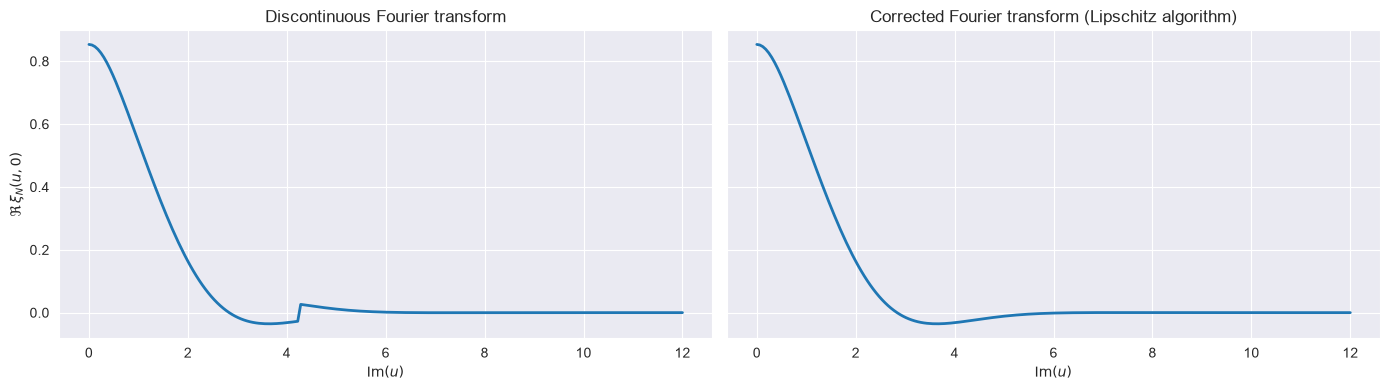

In [12]:
# Model parameters
d = 1
n = 1
N = 100
T = 1.

Y0 = np.array([1.0])

H = 0.1
delta = 0.0

# Correlation and vol-of-vol
C = np.array([[1.0]])                         # shape (d, n)
rho = np.array([[1.0]])                       # covariance of B
R_W = np.array([[1.0]])                       # covariance of W
eta = np.array([[1.0]])                       # shape (n, d)

# Gamma coefficients
Gamma = np.array([[1.0]])                     # shape (d*d, n)

tilde_Gamma = compute_tilde_Gamma(n, d, Gamma)

# Deterministic G0
G0 = np.ones((N, d, d))

# Fractional kernel discretization (delta = 0); apply eta to the eta-free covariance core
KK, SIG_eta_free = shifted_fractional_KK_SIG_d1_n1(
    N=N,
    T=T,
    H=H,
    delta=delta,
)
SIG = np.kron(SIG_eta_free, eta @ eta.T)

# M-matrix
MM = compute_M_matrix(
    n=n,
    d=d,
    N=N,
    SIG=SIG,
    Gamma=Gamma,
    tilde_Gamma=tilde_Gamma,
    rho=rho,
    G0=G0,
    Y0=Y0,
)

# Determinant Fourier–Laplace transform
V_det = compute_V_matrix_for_fourier(
    n,
    N,
    T,
    eta,
    R_W,
    KK,
    SIG,
    MM,
)

g_tilde = compute_tilde_g_N0(Y0, n, N, MM)


# Grid for Im(u)
xi = np.linspace(0, 12, 200)

# u = 1/2 + i * xi
u_array = np.array([[0.5 + 1j * x] for x in xi], dtype=complex)  # shape (len(xi), d)

# w = 0
w_array = np.zeros((len(xi), d, d), dtype=complex)

discontinuous_fourier_laplace_values, det_values = vss_fourier_laplace_discontinuous_det(
    u_array=u_array,
    w_array=w_array,
    n=n,
    d=d,
    N=N,
    T=T,
    C=C,
    rho=rho,
    R_W=R_W,
    V=V_det,
    g_tilde=g_tilde,
)

fourier_laplace_values = vss_fourier_laplace_det_lip_based(discontinuous_fourier_laplace_values, det_values)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

# Gauche : transformée discontinue
axes[0].plot(
    xi,
    np.real(discontinuous_fourier_laplace_values),
    linewidth=2,
)
axes[0].set_xlabel(r"$\mathrm{Im}(u)$")
axes[0].set_ylabel(r"$\Re\,\xi_N(u,0)$")
axes[0].set_title("Discontinuous Fourier transform")
axes[0].grid(True)

# Droite : transformée corrigée (Lipschitz)
axes[1].plot(
    xi,
    np.real(fourier_laplace_values),
    linewidth=2,
)
axes[1].set_xlabel(r"$\mathrm{Im}(u)$")
axes[1].set_title("Corrected Fourier transform (Lipschitz algorithm)")
axes[1].grid(True)

plt.tight_layout()
fig.savefig(
    PLOTS_DIRECTORY / 'lipschitz_algo_sanity_check.png',
    dpi=200,
    bbox_inches='tight',
)
plt.show()

## Fourier vs Monte-Carlo

Each check compares a Fourier value to Monte-Carlo, with **independent number of time discretisations**
`N_fourier` (Fourier) and `N_MC` (Monte-Carlo). Taking `N_MC` large makes MC a proxy of the
continuous model, so the plots show the Fourier discretisation error at `N_fourier` against
"truth": when `N_fourier` is coarse the MC 95% tube need **not** cover the Fourier value (the gap is
the discretisation bias, which is the intended diagnostic). Set `N_MC = N_fourier` for an exact
same-scheme cross-check instead.

Each subsection produces **tube plots**: the Fourier value(s) as horizontal reference line(s), and
the MC cumulative estimate with its 95% confidence band vs the number of paths. `MC`, `batch_mc`,
`N_fourier`, `N_MC` are exposed at the top of each cell (reduce them for a quick run). The **call**
and **volatility swap** checks show three tubes, comparing the **fractional** ($\delta=0$),
**shifted fractional** ($\delta=1/52$) and **sum-of-two-exponentials** ($\kappa=[0.05,\,1.0]$, $c=[0.5,\,0.5]$) kernels; the **FLT** check
shows two tubes (shifted fractional $H=0.1$, $\delta=1/52$, and sum of exponentials $\kappa=[0,\,1]$, $c=[1,\,1]$), with $n=d=1$.

> Grid evaluations of the transform use the **Lipschitz** algorithm
> (`vss_fourier_laplace_discontinuous_det` + `vss_fourier_laplace_det_lip_based`) and the
> **prefactor-free** algorithm (`vss_fourier_laplace_det_prefactor_free`).

In [13]:
def _fmt_num(v):
    """Format a scalar with %.3g, so numbers with 4+ digits switch to scientific notation
    (e.g. 200000 -> "2e+05") while smaller values are shown as-is (e.g. 200 -> "200")."""
    if isinstance(v, bool) or not isinstance(v, (int, float)):
        return v
    return f"{v:.3g}"


def format_params_df(rows):
    """
    Build a parameters DataFrame from (category, parameter, value) rows, formatting
    numeric values (scalars or lists of scalars) with _fmt_num.

    Parameters
    ----------
    rows : list of (str, str, Any)
        (category, parameter, value) tuples.

    Returns
    -------
    pd.DataFrame with columns ["Category", "Parameter", "Value"].
    """
    formatted = [
        (cat, param, [_fmt_num(x) for x in val] if isinstance(val, list) else _fmt_num(val))
        for cat, param, val in rows
    ]
    return pd.DataFrame(formatted, columns=["Category", "Parameter", "Value"])

### Fourier–Laplace transform



$\xi(u,w)$ at a single $(u,w)$: Fourier (Lipschitz and prefactor-free) vs Monte-Carlo, as real-part
tubes. Two panels: a **shifted fractional** kernel ($n=d=1$, $H=0.1$, $\delta=1/52$) and
a **sum of two exponentials** ($\kappa=[0,\,1]$, $c=[1,\,1]$).


/Users/maximeguellil/.venvs/volterra-stein-stein/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2406: RuntimeWarning: divide by zero encountered in det
  r = _umath_linalg.det(a, signature=signature)
/Users/maximeguellil/.venvs/volterra-stein-stein/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2406: RuntimeWarning: overflow encountered in det
  r = _umath_linalg.det(a, signature=signature)
/Users/maximeguellil/.venvs/volterra-stein-stein/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2406: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)


[Shifted fractional kernel ($H=0.1$, $\delta=1/52$)]
  Fourier (Lipschitz) = 0.917163+0.041581j
  Fourier (prefactor) = 0.917163+0.041581j
  MC estimate         = 0.917164+0.041468j  (SE 3.08e-04)
[Sum-of-exp kernel ($\kappa=[0,\ 1]$, $c=[1,\ 1]$)]
  Fourier (Lipschitz) = 0.917736+0.042647j
  Fourier (prefactor) = 0.917736+0.042647j
  MC estimate         = 0.917800+0.042724j  (SE 2.56e-04)


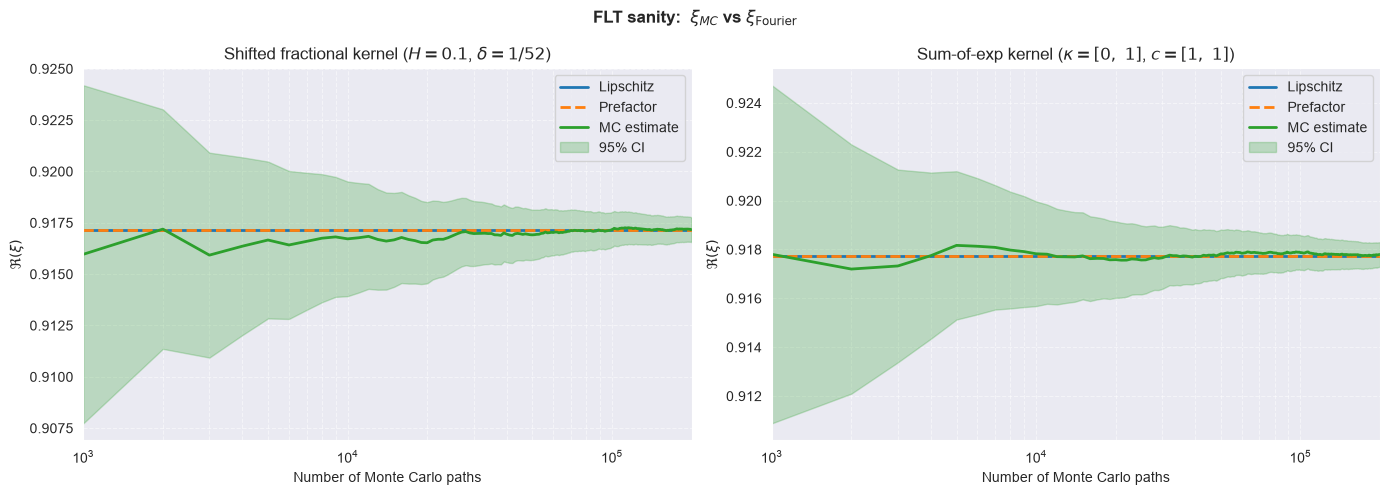

,Category,Parameter,Value
0,Model,d,1
1,Model,n,1
2,Model,T,0.05
3,Model,H,0.1
4,Model,delta,0.0192
5,Model,kappa (sum-of-exp panel),"[0, 1]"
6,Model,c (sum-of-exp panel),"[1, 1]"
7,Model,Y0,[1]
8,Model,C,[[0.5]]
9,Model,rho,[[1.0]]


In [14]:
# ---- Fourier-Laplace transform: Fourier vs Monte-Carlo ----
d = 1
n = 1
T = 0.05
N_fourier = 200          # Fourier discretisation
N_MC = 10**3             # MC discretisation (large = proxy of the continuous model)

Y0 = np.array([1.0])
H = 0.1
delta = 1.0 / 52.0
kappa_exp = np.array([[0.0, 1.0]])          # one constant term and one decaying term
c_exp = np.array([[1.0, 1.0]])

# Laplace / Fourier variables (single point)
u = np.array([0.5 + 1.0j], dtype=complex)
w = np.array([[-1.0 + 1.0j]], dtype=complex)

# Correlation and vol-of-vol
C = np.array([[0.5]])
rho = np.array([[1.0]])
R_W = np.array([[1.0]])
eta = np.array([[1.0]])
Gamma = np.array([[0.7]])
tilde_Gamma = compute_tilde_Gamma(n, d, Gamma)

MC = 2 * 10**5
batch_mc = 10**3

# ---- Consistent styling ----
COL_LIP, LS_LIP = "C0", "-"       # Lipschitz (Fourier)
COL_PF,  LS_PF = "C1", "--"       # Prefactor (Fourier)
COL_MC,  LS_MC = "C2", "-"        # Monte-Carlo estimate
COL_CI,  LS_CI = "C2", ":"        # 95% confidence interval

z95 = st.norm.ppf(0.975)

# Two kernels: shifted fractional and sum of two exponentials. Each builder maps N -> (KK, SIG_eta_free).
kernel_configs = [
    (rf"Shifted fractional kernel ($H={H}$, $\delta=1/52$)",
     lambda N_: shifted_fractional_KK_SIG_d1_n1(N=N_, T=T, H=H, delta=delta)),
    (r"Sum-of-exp kernel ($\kappa=[0,\ 1]$, $c=[1,\ 1]$)",
     lambda N_: sum_exponential_KK_SIG_d1_n1(N=N_, T=T, kappa_array=kappa_exp, c_array=c_exp)),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (kernel_title, kernel_builder) in zip(axes, kernel_configs):
    # ---- Fourier side (N_fourier) ----
    KK_f, SIG_eta_free_f = kernel_builder(N_fourier)
    SIG_f = np.kron(SIG_eta_free_f, eta @ eta.T)
    G0_f = np.ones((N_fourier, d, d))
    MM_f = compute_M_matrix(n=n, d=d, N=N_fourier, SIG=SIG_f, Gamma=Gamma, tilde_Gamma=tilde_Gamma, rho=rho, G0=G0_f, Y0=Y0)
    V_det = compute_V_matrix_for_fourier(n, N_fourier, T, eta, R_W, KK_f, SIG_f, MM_f)
    sqrt_V_det = matrix_sqrt_psd(V_det)
    g_tilde = compute_tilde_g_N0(Y0, n, N_fourier, MM_f)

    xi_det_lip, _ = _vss_fourier_laplace_discontinuous_eval_unique_det(u, w, n, d, N_fourier, T, C, rho, R_W, V_det, g_tilde)
    xi_det_pf = _vss_fourier_laplace_eval_unique_det_prefactor_free(u, w, n, d, N_fourier, T, C, rho, R_W, V_det, sqrt_V_det, g_tilde)

    # ---- Monte-Carlo side (N_MC) ----
    KK_m, SIG_eta_free_m = kernel_builder(N_MC)
    SIG_m = np.kron(SIG_eta_free_m, eta @ eta.T)
    G0_m = np.ones((N_MC, d, d))
    MM_m = compute_M_matrix(n=n, d=d, N=N_MC, SIG=SIG_m, Gamma=Gamma, tilde_Gamma=tilde_Gamma, rho=rho, G0=G0_m, Y0=Y0)
    V_mc = compute_V_matrix_for_mc(d, N_MC, T, eta, C, rho, KK_m, SIG_m, MM_m)
    chol_V_mc = spectral_cholesky(V_mc, tol=1e-12)

    mc_paths, mc_mean, mc_std = _vss_fourier_laplace_eval_unique_mc(
        u=u, w=w, d=d, N=N_MC, T=T, Y0=Y0, rho=rho, MM=MM_m, chol_V=chol_V_mc,
        MC=MC, batch_mc=batch_mc, seed=None, use_antithetic=True,
    )
    MC_path = np.asarray(mc_paths, dtype=int)
    xi_path = np.asarray(mc_mean, dtype=complex)
    se_path = np.asarray(mc_std)

    # ---- Real-part tube ----
    ax.axhline(np.real(xi_det_lip), color=COL_LIP, ls=LS_LIP, linewidth=2, label="Lipschitz")
    ax.axhline(np.real(xi_det_pf), color=COL_PF, ls=LS_PF, linewidth=2, label="Prefactor")
    ax.plot(MC_path, np.real(xi_path), color=COL_MC, ls=LS_MC, linewidth=2, label="MC estimate")
    ax.fill_between(MC_path, np.real(xi_path) - z95 * se_path, np.real(xi_path) + z95 * se_path,
                    color=COL_CI, alpha=0.25, label="95% CI")
    ax.set_xscale("log")
    ax.set_xlim(MC_path[0], MC_path[-1])
    ax.set_xlabel("Number of Monte Carlo paths")
    ax.set_ylabel(r"$\Re\left(\xi\right)$")
    ax.set_title(kernel_title)
    ax.grid(True, which="both", ls="--", alpha=0.5)
    ax.legend()

    print(f"[{kernel_title}]")
    print(f"  Fourier (Lipschitz) = {xi_det_lip:.6f}")
    print(f"  Fourier (prefactor) = {xi_det_pf:.6f}")
    print(f"  MC estimate         = {xi_path[-1]:.6f}  (SE {se_path[-1]:.2e})")

fig.suptitle(r"FLT sanity:  $\xi_{MC}$ vs $\xi_{\mathrm{Fourier}}$", fontweight="bold")
plt.tight_layout()
plt.tight_layout()
fig.savefig(
    PLOTS_DIRECTORY / 'flt_fourier_vs_mc.png',
    dpi=200,
    bbox_inches='tight',
)
plt.show()

# ---- Parameters used in this sanity check ----
params_df = format_params_df([
    ("Model", "d", d),
    ("Model", "n", n),
    ("Model", "T", T),
    ("Model", "H", H),
    ("Model", "delta", delta),
    ("Model", "kappa (sum-of-exp panel)", kappa_exp.ravel().tolist()),
    ("Model", "c (sum-of-exp panel)", c_exp.ravel().tolist()),
    ("Model", "Y0", Y0.tolist()),
    ("Model", "C", C.tolist()),
    ("Model", "rho", rho.tolist()),
    ("Model", "R_W", R_W.tolist()),
    ("Model", "eta", eta.tolist()),
    ("Model", "Gamma", Gamma.tolist()),
    ("Model", "u", u.tolist()),
    ("Model", "w", w.tolist()),
    ("Fourier", "N_fourier", N_fourier),
    ("Monte-Carlo", "N_MC", N_MC),
    ("Monte-Carlo", "MC", MC),
    ("Monte-Carlo", "batch_mc", batch_mc),
])
display(params_df)

### European call

ATM call ($d=1$, $n=1$, $H=0.3$, $K=S_0=1$): Fourier prices (Lewis inversion of $\xi(1/2+iu,0)$ on
Gauss–Laguerre nodes, Lipschitz and prefactor-free) vs Monte-Carlo, as tubes. Three panels compare the
**fractional** kernel ($\delta=0$), the **shifted fractional** kernel ($\delta=1/52$), and the
**sum of two exponentials** ($\kappa=[0.05,\,1]$, $c=[0.5,\,0.5]$).

[Fractional kernel ($H=0.3$)]
  Fourier (Lipschitz) call = 0.087469   put = 0.087469
  Fourier (prefactor) call = 0.087469   put = 0.087469
  MC       call = 0.087398 +/- 0.000768   put = 0.087657 +/- 0.000457  (95% CI)
[Shifted fractional kernel ($H=0.3$, $\delta=1/52$)]
  Fourier (Lipschitz) call = 0.088132   put = 0.088132
  Fourier (prefactor) call = 0.088132   put = 0.088132
  MC       call = 0.087856 +/- 0.000746   put = 0.088198 +/- 0.000462  (95% CI)
[Sum-of-exp kernel ($\kappa=[0.05,\ 1]$, $c=[\frac{1}{2},\frac{1}{2}]$)]
  Fourier (Lipschitz) call = 0.088898   put = 0.088898
  Fourier (prefactor) call = 0.088898   put = 0.088898
  MC       call = 0.089007 +/- 0.000711   put = 0.088602 +/- 0.000478  (95% CI)


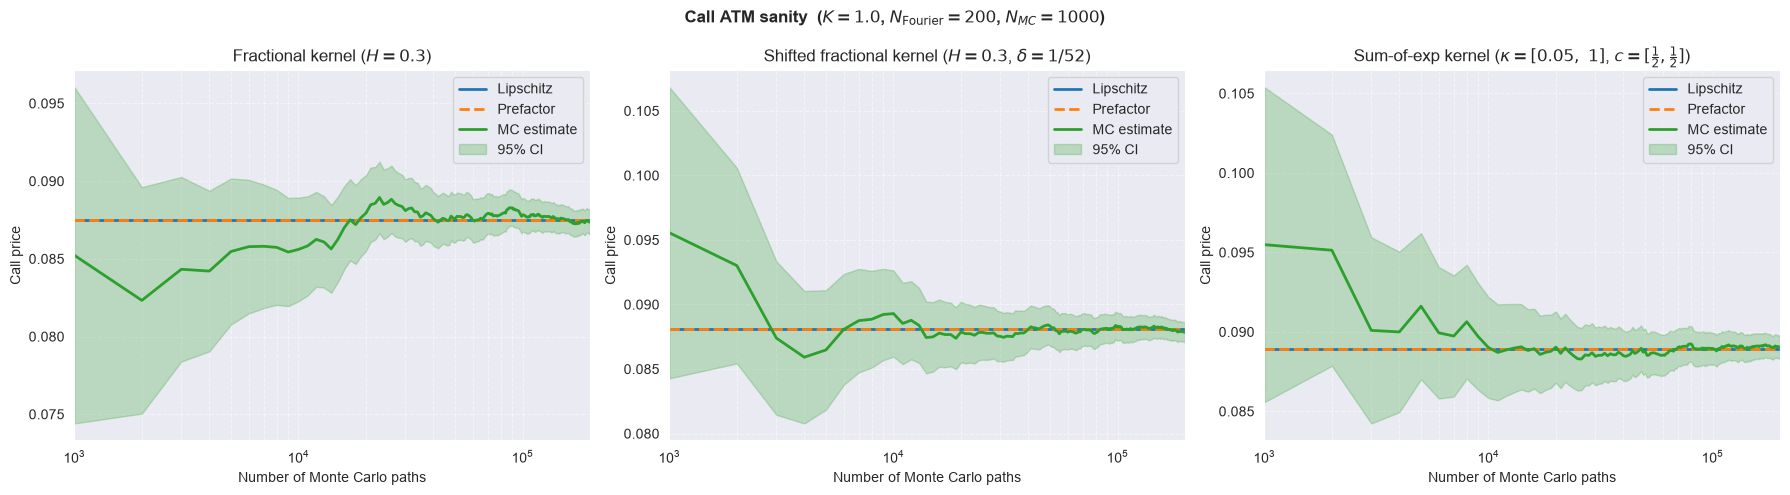

,Category,Parameter,Value
0,Model,d,1
1,Model,n,1
2,Model,T,0.05
3,Model,H,0.3
4,Model,delta (shifted panel),0.0192
5,Model,kappa (sum-of-exp panel),"[0.05, 1]"
6,Model,c (sum-of-exp panel),"[0.5, 0.5]"
7,Model,Y0,[1]
8,Model,C,[[0.5]]
9,Model,rho,[[1.0]]


In [15]:
# ---- European call (ATM, H = 0.3): Fourier vs Monte-Carlo, three kernels ----
d = 1
n = 1
T = 0.05
N_fourier = 200
N_MC = 10**3

S_0 = 1.0
K_atm = 1.0
Y0 = np.array([1.0])
H = 0.3

C = np.array([[0.5]])            # correlation between B and W
rho = np.array([[1.0]])
R_W = np.array([[1.0]])
eta = np.array([[1.0]])
Gamma = np.array([[1.0]])
tilde_Gamma = compute_tilde_Gamma(n, d, Gamma)

MC = 2 * 10**5
batch_mc = 10**3

# Gauss-Laguerre quadrature for the Lewis inversion (moderate degree; high degrees are unstable)
gl_deg = 80
gl_nodes, gl_weights = np.polynomial.laguerre.laggauss(gl_deg)

z95 = st.norm.ppf(0.975)

# ---- Consistent styling across the panels ----
COL_LIP, LS_LIP = "C0", "-"       # Lipschitz (Fourier)
COL_PF,  LS_PF = "C1", "--"       # Prefactor (Fourier)
COL_MC,  LS_MC = "C2", "-"        # Monte-Carlo estimate
COL_CI,  LS_CI = "C2", ":"        # 95% confidence interval

# Three kernels: fractional, shifted fractional, sum of two exponentials.
# Each builder maps N -> (KK, SIG_eta_free).
kernel_configs = [
    (rf"Fractional kernel ($H={H}$)",
     lambda N_: shifted_fractional_KK_SIG_d1_n1(N=N_, T=T, H=H, delta=0.0)),
    (rf"Shifted fractional kernel ($H={H}$, $\delta=1/52$)",
     lambda N_: shifted_fractional_KK_SIG_d1_n1(N=N_, T=T, H=H, delta=1.0 / 52.0)),
    (r"Sum-of-exp kernel ($\kappa=[0.05,\ 1]$, $c=[\frac{1}{2},\frac{1}{2}]$)",
     lambda N_: sum_exponential_KK_SIG_d1_n1(N=N_, T=T, kappa_array=np.array([[0.05, 1.0]]), c_array=np.array([[0.5, 0.5]]))),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (kernel_title, kernel_builder) in zip(axes, kernel_configs):
    # ---- Fourier side (N_fourier) ----
    KK_f, SIG_eta_free_f = kernel_builder(N_fourier)
    SIG_f = np.kron(SIG_eta_free_f, eta @ eta.T)
    G0_f = np.ones((N_fourier, d, d))
    MM_f = compute_M_matrix(n=n, d=d, N=N_fourier, SIG=SIG_f, Gamma=Gamma, tilde_Gamma=tilde_Gamma, rho=rho, G0=G0_f, Y0=Y0)
    V_det = compute_V_matrix_for_fourier(n, N_fourier, T, eta, R_W, KK_f, SIG_f, MM_f)
    sqrt_V_det = matrix_sqrt_psd(V_det)
    g_tilde = compute_tilde_g_N0(Y0, n, N_fourier, MM_f)

    # xi(1/2 + i s) with w = 0 on the Gauss-Laguerre nodes: Lipschitz and prefactor-free
    u_array = (0.5 + 1j * gl_nodes).reshape(-1, 1)
    w_array = np.zeros((gl_deg, d, d), dtype=complex)
    disc_vals, det_vals = vss_fourier_laplace_discontinuous_det(u_array, w_array, n, d, N_fourier, T, C, rho, R_W, V_det, g_tilde)
    flt_vals_lip = vss_fourier_laplace_det_lip_based(disc_vals, det_vals)
    flt_vals_pf = vss_fourier_laplace_det_prefactor_free(u_array, w_array, n, d, N_fourier, T, C, rho, R_W, V_det, sqrt_V_det, g_tilde)

    put_fourier_lip, call_fourier_lip = call_put_price_fourier(flt_vals_lip, S_0, np.array([K_atm]), gl_nodes, gl_weights, option_type="both")
    put_fourier_lip, call_fourier_lip = put_fourier_lip[0], call_fourier_lip[0]
    put_fourier_pf, call_fourier_pf = call_put_price_fourier(flt_vals_pf, S_0, np.array([K_atm]), gl_nodes, gl_weights, option_type="both")
    put_fourier_pf, call_fourier_pf = put_fourier_pf[0], call_fourier_pf[0]

    # ---- Monte-Carlo side (N_MC) ----
    KK_m, SIG_eta_free_m = kernel_builder(N_MC)
    SIG_m = np.kron(SIG_eta_free_m, eta @ eta.T)
    G0_m = np.ones((N_MC, d, d))
    MM_m = compute_M_matrix(n=n, d=d, N=N_MC, SIG=SIG_m, Gamma=Gamma, tilde_Gamma=tilde_Gamma, rho=rho, G0=G0_m, Y0=Y0)
    V_mc = compute_V_matrix_for_mc(d, N_MC, T, eta, C, rho, KK_m, SIG_m, MM_m)
    chol_V_mc = spectral_cholesky(V_mc, tol=1e-12)

    MC_path, put_path, call_path, put_std, call_std = mc_call_put_price(
        S_0, np.array([K_atm]), d=d, N=N_MC, T=T, Y0=Y0, rho=rho, MM=MM_m, chol_V=chol_V_mc,
        MC=MC, batch_mc=batch_mc, seed=None, use_antithetic=False, option_type="both",
    )
    call_mc, call_se = call_path[:, 0], call_std[:, 0]

    # ---- Tube on the Call price ----
    ax.axhline(call_fourier_lip, color=COL_LIP, ls=LS_LIP, linewidth=2, label="Lipschitz")
    ax.axhline(call_fourier_pf, color=COL_PF, ls=LS_PF, linewidth=2, label="Prefactor")
    ax.plot(MC_path, call_mc, color=COL_MC, ls=LS_MC, linewidth=2, label="MC estimate")
    ax.fill_between(MC_path, call_mc - z95 * call_se, call_mc + z95 * call_se,
                    color=COL_CI, alpha=0.25, label="95% CI")
    ax.set_xscale("log")
    ax.set_xlim(MC_path[0], MC_path[-1])
    ax.set_xlabel("Number of Monte Carlo paths")
    ax.set_ylabel("Call price")
    ax.set_title(kernel_title)
    ax.grid(True, which="both", ls="--", alpha=0.5)
    ax.legend()

    print(f"[{kernel_title}]")
    print(f"  Fourier (Lipschitz) call = {call_fourier_lip:.6f}   put = {put_fourier_lip:.6f}")
    print(f"  Fourier (prefactor) call = {call_fourier_pf:.6f}   put = {put_fourier_pf:.6f}")
    print(f"  MC       call = {call_path[-1,0]:.6f} +/- {z95*call_std[-1,0]:.6f}   "
          f"put = {put_path[-1,0]:.6f} +/- {z95*put_std[-1,0]:.6f}  (95% CI)")

fig.suptitle(rf"Call ATM sanity  ($K={K_atm}$, "
             rf"$N_{{\mathrm{{Fourier}}}}={N_fourier}$, $N_{{MC}}={N_MC}$)", fontweight="bold")
plt.tight_layout()
plt.tight_layout()
fig.savefig(
    PLOTS_DIRECTORY / 'call_fourier_vs_mc.png',
    dpi=200,
    bbox_inches='tight',
)
plt.show()

# ---- Parameters used in this sanity check ----
params_df = format_params_df([
    ("Model", "d", d),
    ("Model", "n", n),
    ("Model", "T", T),
    ("Model", "H", H),
    ("Model", "delta (shifted panel)", 1.0 / 52.0),
    ("Model", "kappa (sum-of-exp panel)", [0.05, 1.0]),
    ("Model", "c (sum-of-exp panel)", [0.5, 0.5]),
    ("Model", "Y0", Y0.tolist()),
    ("Model", "C", C.tolist()),
    ("Model", "rho", rho.tolist()),
    ("Model", "R_W", R_W.tolist()),
    ("Model", "eta", eta.tolist()),
    ("Model", "Gamma", Gamma.tolist()),
    ("Model", "S_0", S_0),
    ("Model", "K_atm", K_atm),
    ("Fourier", "N_fourier", N_fourier),
    ("Fourier", "gl_deg", gl_deg),
    ("Monte-Carlo", "N_MC", N_MC),
    ("Monte-Carlo", "MC", MC),
    ("Monte-Carlo", "batch_mc", batch_mc),
])
display(params_df)

### European basket call

ATM call on the equally weighted arithmetic basket $B_T=(S_T^1+S_T^2)/2$ in the
$d=n=2$ model of Example 1.1, with $S_0^1=S_0^2=K=1$. The Fourier prices use the
Lipschitz-based and prefactor-free transforms on two joint quadrants and separate marginal Lewis grids. The
Monte-Carlo estimate and its 95% confidence tube use the same complete basket payoff. Three
panels compare a fractional plus shifted-fractional pair, two exponential kernels, and a
shifted-fractional plus exponential pair.

[Fractional + shifted fractional ($H=[0.15,-0.3]$, $\delta=[0,1/52]$)]
  Lipschitz basket call      = 0.060055
  Prefactor-free basket call = 0.060055
  MC basket call = 0.060036 +/- 0.000527 (95% CI)
[Two exponential kernels ($\kappa=[0.25,2]$)]
  Lipschitz basket call      = 0.062585
  Prefactor-free basket call = 0.062585
  MC basket call = 0.062249 +/- 0.000594 (95% CI)


KeyboardInterrupt: 

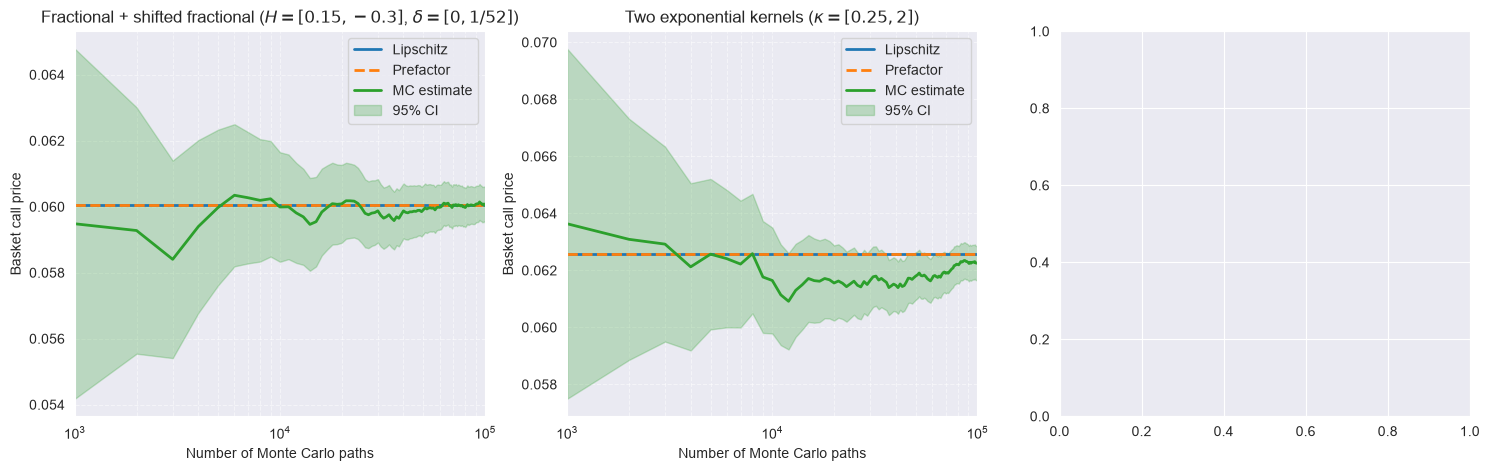

In [16]:
# ---- European basket call (ATM, d = n = 2): Fourier vs Monte-Carlo ----
d = 2
n = 2
T = 0.05
N_fourier = 30
N_MC = 10**3

S_0 = np.ones(2)
K_atm = 1.0
Y0 = np.ones(2)

nu = np.array([0.6, 0.8])
eta = np.diag(nu)
rho_12 = 0.35
rho = np.array([
    [1.0, rho_12],
    [rho_12, 1.0],
])
C = np.diag([-0.70, -0.50])
R_W = C.T @ rho @ C + np.eye(n) - np.diag(np.diag(C.T @ C))

# Column-major vec(Z) = (Z_11, Z_21, Z_12, Z_22).
Gamma = np.array([
    [1.0, 0.0],
    [0.0, 0.0],
    [0.0, 0.0],
    [0.0, 1.0],
])
tilde_Gamma = compute_tilde_Gamma(n, d, Gamma)

alpha = np.array([0.33, 0.33])
joint_gl_degree = 80
marginal_gl_degree = 80
joint_sample_points, joint_weights = np.polynomial.laguerre.laggauss(
    joint_gl_degree
)
marginal_sample_points, marginal_weights = np.polynomial.laguerre.laggauss(
    marginal_gl_degree
)

MC = 100_000
batch_mc = 1_000
seed = 12345
use_antithetic = False
z95 = st.norm.ppf(0.975)

# Parameters of the three kernel panels.
H_array_basket = np.array([0.15, -0.3])
delta_array_basket = np.array([0.0, 1.0 / 52.0])
kappa_array_basket = np.array([[0.25], [2.0]])
c_array_basket = np.ones((2, 1))
H_mixed_basket = 0.25
delta_mixed_basket = 1.0 / 52.0
kappa_mixed_basket = np.array([[1.0]])
c_mixed_basket = np.array([[1.0]])

COL_LIP, LS_LIP = "C0", "-"
COL_PF, LS_PF = "C1", "--"
COL_MC, LS_MC = "C2", "-"
COL_CI = "C2"

kernel_configs = [
    (
        rf"Fractional + shifted fractional ($H=[0.15,-0.3]$, $\delta=[0,1/52]$)",
        lambda N_: shifted_fractional_KK_SIG_d2_n2(
            N=N_,
            T=T,
            H_array=H_array_basket,
            delta_array=delta_array_basket,
        ),
    ),
    (
        r"Two exponential kernels ($\kappa=[0.25,2]$)",
        lambda N_: sum_exponential_KK_SIG_d2_n2(
            N=N_,
            T=T,
            kappa_array=kappa_array_basket,
            c_array=c_array_basket,
        ),
    ),
    (
        rf"Shifted fractional + exponential ($H={H_mixed_basket}$, $\delta=1/52$, $\kappa=1$)",
        lambda N_: shifted_fractional_sum_exponential_KK_SIG_d2_n2(
            N=N_,
            T=T,
            H=H_mixed_basket,
            delta=delta_mixed_basket,
            kappa_array=kappa_mixed_basket,
            c_array=c_mixed_basket,
            order="frac-exp",
        ),
    ),
]

# The two joint quadrants required by basket_call_put_price_fourier.
x_1, x_2 = np.meshgrid(
    joint_sample_points,
    joint_sample_points,
    indexing="ij",
)
joint_u_array = np.vstack([
    np.column_stack([
        alpha[0] - 1j * x_1.ravel(),
        alpha[1] - 1j * x_2.ravel(),
    ]),
    np.column_stack([
        alpha[0] - 1j * x_1.ravel(),
        alpha[1] + 1j * x_2.ravel(),
    ]),
])
joint_w_array = np.zeros(
    (joint_u_array.shape[0], d, d),
    dtype=complex,
)

# Marginal transforms used by the one-dimensional Lewis terms.
marginal_u_array = np.vstack([
    np.column_stack([
        0.5 + 1j * marginal_sample_points,
        np.zeros(marginal_gl_degree),
    ]),
    np.column_stack([
        np.zeros(marginal_gl_degree),
        0.5 + 1j * marginal_sample_points,
    ]),
])
marginal_w_array = np.zeros(
    (marginal_u_array.shape[0], d, d),
    dtype=complex,
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (kernel_title, kernel_builder) in zip(axes, kernel_configs):
    # ---- Fourier side (N_fourier) ----
    KK_f, SIG_integrals_f = kernel_builder(N_fourier)
    SIG_f = compute_SIG_matrix_d2_n2(SIG_integrals_f, nu, R_W)
    G0_f = np.tile(np.eye(d), (N_fourier, 1, 1))
    MM_f = compute_M_matrix(
        n=n, d=d, N=N_fourier, SIG=SIG_f, Gamma=Gamma,
        tilde_Gamma=tilde_Gamma, rho=rho, G0=G0_f, Y0=Y0,
    )
    V_det = compute_V_matrix_for_fourier(
        n, N_fourier, T, eta, R_W, KK_f, SIG_f, MM_f
    )
    sqrt_V_det = matrix_sqrt_psd(V_det)
    g_tilde = compute_tilde_g_N0(Y0, n, N_fourier, MM_f)

    # Lipschitz values on continuous snake paths, anchored at the real point alpha.
    joint_fourier_laplace_values_lip = np.zeros(
        (2, joint_gl_degree, joint_gl_degree), dtype=complex
    )
    for quadrant, sign_2 in enumerate((1.0, -1.0)):
        joint_u_path = [alpha.astype(complex)]
        matrix_indices = []
        for i, x_1_value in enumerate(joint_sample_points):
            j_indices = (
                range(joint_gl_degree)
                if i % 2 == 0
                else range(joint_gl_degree - 1, -1, -1)
            )
            for j in j_indices:
                x_2_value = joint_sample_points[j]
                joint_u_path.append([
                    alpha[0] - 1j * x_1_value,
                    alpha[1] - 1j * sign_2 * x_2_value,
                ])
                matrix_indices.append((i, j))

        joint_u_path = np.asarray(joint_u_path, dtype=complex)
        joint_w_path = np.zeros(
            (len(joint_u_path), d, d), dtype=complex
        )
        joint_disc_values, joint_det_values = (
            vss_fourier_laplace_discontinuous_det(
                joint_u_path, joint_w_path, n, d, N_fourier, T, C, rho,
                R_W, V_det, g_tilde,
            )
        )
        joint_lip_path = vss_fourier_laplace_det_lip_based(
            joint_disc_values, joint_det_values
        )[1:]
        for value, (i, j) in zip(joint_lip_path, matrix_indices):
            joint_fourier_laplace_values_lip[quadrant, i, j] = value

    joint_values_pf_flat = vss_fourier_laplace_det_prefactor_free(
        joint_u_array, joint_w_array, n, d, N_fourier, T, C, rho,
        R_W, V_det, sqrt_V_det, g_tilde,
    )
    joint_fourier_laplace_values_pf = joint_values_pf_flat.reshape(
        2, joint_gl_degree, joint_gl_degree
    )

    marginal_fourier_laplace_values_lip = np.zeros(
        (2, marginal_gl_degree), dtype=complex
    )
    for asset in range(2):
        marginal_u_path = np.zeros(
            (marginal_gl_degree + 1, d), dtype=complex
        )
        marginal_u_path[0, asset] = 0.5
        marginal_u_path[1:, asset] = (
            0.5 + 1j * marginal_sample_points
        )
        marginal_w_path = np.zeros(
            (marginal_gl_degree + 1, d, d), dtype=complex
        )
        marginal_disc_values, marginal_det_values = (
            vss_fourier_laplace_discontinuous_det(
                marginal_u_path, marginal_w_path, n, d, N_fourier, T, C,
                rho, R_W, V_det, g_tilde,
            )
        )
        marginal_fourier_laplace_values_lip[asset] = (
            vss_fourier_laplace_det_lip_based(
                marginal_disc_values, marginal_det_values
            )[1:]
        )

    marginal_values_pf_flat = vss_fourier_laplace_det_prefactor_free(
        marginal_u_array, marginal_w_array, n, d, N_fourier, T, C, rho,
        R_W, V_det, sqrt_V_det, g_tilde,
    )
    marginal_fourier_laplace_values_pf = marginal_values_pf_flat.reshape(
        2, marginal_gl_degree
    )

    call_fourier_lip = basket_call_put_price_fourier(
        joint_fourier_laplace_values=joint_fourier_laplace_values_lip,
        marginal_fourier_laplace_values=marginal_fourier_laplace_values_lip,
        S_0=S_0,
        K_array=np.array([K_atm]),
        alpha=alpha,
        joint_sample_points=joint_sample_points,
        joint_weights=joint_weights,
        marginal_sample_points=marginal_sample_points,
        marginal_weights=marginal_weights,
        option_type="call",
    )[0]

    call_fourier_pf = basket_call_put_price_fourier(
        joint_fourier_laplace_values=joint_fourier_laplace_values_pf,
        marginal_fourier_laplace_values=marginal_fourier_laplace_values_pf,
        S_0=S_0,
        K_array=np.array([K_atm]),
        alpha=alpha,
        joint_sample_points=joint_sample_points,
        joint_weights=joint_weights,
        marginal_sample_points=marginal_sample_points,
        marginal_weights=marginal_weights,
        option_type="call",
    )[0]

    # ---- Monte-Carlo side (N_MC) ----
    KK_m, SIG_integrals_m = kernel_builder(N_MC)
    SIG_m = compute_SIG_matrix_d2_n2(SIG_integrals_m, nu, R_W)
    G0_m = np.tile(np.eye(d), (N_MC, 1, 1))
    MM_m = compute_M_matrix(
        n=n, d=d, N=N_MC, SIG=SIG_m, Gamma=Gamma,
        tilde_Gamma=tilde_Gamma, rho=rho, G0=G0_m, Y0=Y0,
    )
    V_mc = compute_V_matrix_for_mc(
        d, N_MC, T, eta, C, rho, KK_m, SIG_m, MM_m
    )
    chol_V_mc = spectral_cholesky(V_mc, tol=1e-12)

    MC_path, call_path, call_std = mc_basket_call_put_price(
        S_0=S_0,
        K_array=np.array([K_atm]),
        d=d,
        N=N_MC,
        T=T,
        Y0=Y0,
        rho=rho,
        MM=MM_m,
        chol_V=chol_V_mc,
        MC=MC,
        batch_mc=batch_mc,
        seed=seed,
        use_antithetic=use_antithetic,
        option_type="call",
        return_std_error=True,
    )
    call_mc = call_path[:, 0]
    call_se = call_std[:, 0]

    ax.axhline(
        call_fourier_lip, color=COL_LIP, ls=LS_LIP, linewidth=2,
        label="Lipschitz",
    )
    ax.axhline(
        call_fourier_pf, color=COL_PF, ls=LS_PF, linewidth=2,
        label="Prefactor",
    )
    ax.plot(
        MC_path, call_mc, color=COL_MC, ls=LS_MC, linewidth=2,
        label="MC estimate",
    )
    ax.fill_between(
        MC_path, call_mc - z95 * call_se, call_mc + z95 * call_se,
        color=COL_CI, alpha=0.25, label="95% CI",
    )
    ax.set_xscale("log")
    ax.set_xlim(MC_path[0], MC_path[-1])
    ax.set_xlabel("Number of Monte Carlo paths")
    ax.set_ylabel("Basket call price")
    ax.set_title(kernel_title)
    ax.grid(True, which="both", ls="--", alpha=0.5)
    ax.legend()

    print(f"[{kernel_title}]")
    print(f"  Lipschitz basket call      = {call_fourier_lip:.6f}")
    print(f"  Prefactor-free basket call = {call_fourier_pf:.6f}")
    print(
        f"  MC basket call = {call_path[-1, 0]:.6f} "
        f"+/- {z95 * call_std[-1, 0]:.6f} (95% CI)"
    )

fig.suptitle(
    rf"Basket call ATM sanity ($K={K_atm}$, "
    rf"$N_{{\mathrm{{Fourier}}}}={N_fourier}$, $N_{{MC}}={N_MC}$)",
    fontweight="bold",
)
plt.tight_layout()
fig.savefig(
    PLOTS_DIRECTORY / 'basket_call_fourier_vs_mc.png',
    dpi=200,
    bbox_inches='tight',
)
plt.show()

# ---- Parameters used in this sanity check ----
params_df = format_params_df([
    ("Model", "d", d),
    ("Model", "n", n),
    ("Model", "T", T),
    ("Model", "Y0", Y0.tolist()),
    ("Model", "nu", nu.tolist()),
    ("Model", "eta", eta.tolist()),
    ("Model", "C", C.tolist()),
    ("Model", "rho", rho.tolist()),
    ("Model", "R_W", R_W.tolist()),
    ("Model", "Gamma", Gamma.tolist()),
    ("Model", "S_0", S_0.tolist()),
    ("Model", "K_atm", K_atm),
    ("Kernels", "H (fractional panel)", H_array_basket.tolist()),
    ("Kernels", "delta (fractional panel)", delta_array_basket.tolist()),
    ("Kernels", "kappa (exponential panel)", kappa_array_basket.tolist()),
    ("Kernels", "c (exponential panel)", c_array_basket.tolist()),
    ("Kernels", "H (mixed panel)", H_mixed_basket),
    ("Kernels", "delta (mixed panel)", delta_mixed_basket),
    ("Kernels", "kappa (mixed panel)", kappa_mixed_basket.tolist()),
    ("Kernels", "c (mixed panel)", c_mixed_basket.tolist()),
    ("Fourier", "N_fourier", N_fourier),
    ("Fourier", "alpha", alpha.tolist()),
    ("Fourier", "joint_gl_degree", joint_gl_degree),
    ("Fourier", "marginal_gl_degree", marginal_gl_degree),
    ("Monte-Carlo", "N_MC", N_MC),
    ("Monte-Carlo", "MC", MC),
    ("Monte-Carlo", "batch_mc", batch_mc),
    ("Monte-Carlo", "seed", seed),
    ("Monte-Carlo", "use_antithetic", use_antithetic),
])
display(params_df)

### European call vs call


ATM Call vs Call in the $d=n=2$ model of Example 1.1, with $S_0^1=S_0^2=K=1$ and pathwise payoff

$$
\frac12(S_T^1-1)^+ + \frac12(S_T^2-1)^+
-\left(\frac{S_T^1+S_T^2}{2}-1\right)^+.
$$

The Fourier price uses the same joint and marginal transforms as the preceding basket-call sanity check. The Monte-Carlo payoff is computed pathwise from the same pair of simulated terminal assets, rather than by subtracting independent price estimates. The three kernel configurations and every model and numerical parameter are identical to the European basket-call subsection.


/Users/maximeguellil/.venvs/volterra-stein-stein/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2406: RuntimeWarning: divide by zero encountered in det
  r = _umath_linalg.det(a, signature=signature)
/Users/maximeguellil/.venvs/volterra-stein-stein/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2406: RuntimeWarning: divide by zero encountered in det
  r = _umath_linalg.det(a, signature=signature)
/Users/maximeguellil/.venvs/volterra-stein-stein/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2406: RuntimeWarning: divide by zero encountered in det
  r = _umath_linalg.det(a, signature=signature)
/Users/maximeguellil/.venvs/volterra-stein-stein/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2406: RuntimeWarning: overflow encountered in det
  r = _umath_linalg.det(a, signature=signature)
/Users/maximeguellil/.venvs/volterra-stein-stein/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2406: RuntimeWarning: overflow encountered in det
  r = _umath_linalg.det(a, sig

[Fractional + shifted fractional ($H=[0.15,-0.3]$, $\delta=[0,1/52]$)]
  Lipschitz call vs call      = 0.024524
  Prefactor-free call vs call = 0.024524
  MC call vs call = 0.024494 +/- 0.000236 (95% CI)
[Two exponential kernels ($\kappa=[0.25,2]$)]
  Lipschitz call vs call      = 0.025682
  Prefactor-free call vs call = 0.025682
  MC call vs call = 0.025665 +/- 0.000242 (95% CI)
[Shifted fractional + exponential ($H=0.25$, $\delta=1/52$, $\kappa=1$)]
  Lipschitz call vs call      = 0.025627
  Prefactor-free call vs call = 0.025627
  MC call vs call = 0.025536 +/- 0.000241 (95% CI)


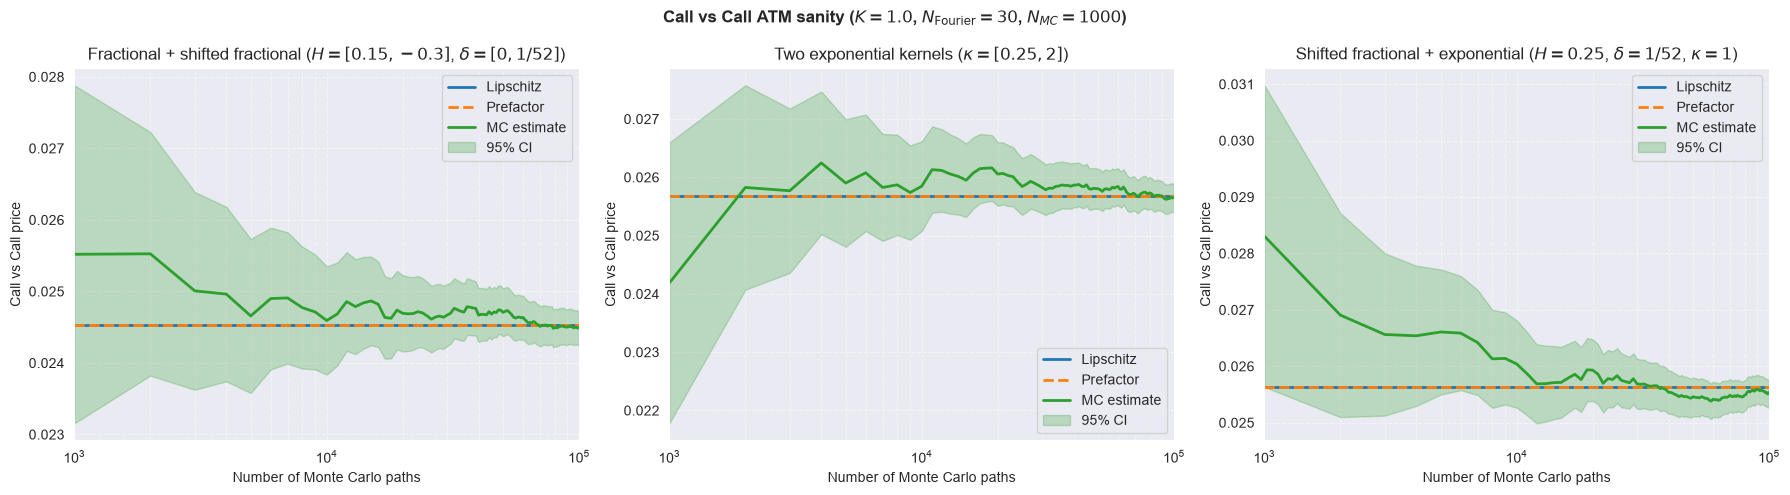

,Kernel configuration,Fourier Lipschitz,Fourier prefactor-free,Monte-Carlo,Monte-Carlo standard error,95% CI lower,95% CI upper,MC - Lipschitz,MC - prefactor-free
0,"Fractional + shifted fractional ($H=[0.15,-0.3...",0.024524,0.024524,0.024494,0.000121,0.024258,0.024730,-0.000030,-0.000030
1,"Two exponential kernels ($\kappa=[0.25,2]$)",0.025682,0.025682,0.025665,0.000124,0.025423,0.025907,-0.000017,-0.000017
2,"Shifted fractional + exponential ($H=0.25$, $\...",0.025627,0.025627,0.025536,0.000123,0.025294,0.025777,-0.000092,-0.000092


,Category,Parameter,Value
0,Model,d,2
1,Model,n,2
2,Model,T,0.05
3,Model,Y0,"[1, 1]"
4,Model,nu,"[0.6, 0.8]"
5,Model,eta,"[[0.6, 0.0], [0.0, 0.8]]"
6,Model,C,"[[-0.7, 0.0], [0.0, -0.5]]"
7,Model,rho,"[[1.0, 0.35], [0.35, 1.0]]"
8,Model,R_W,"[[1.0, 0.12249999999999998], [0.12249999999999..."
9,Model,Gamma,"[[1.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 1.0]]"


In [17]:
# ---- European call vs call (ATM, d = n = 2): Fourier vs Monte-Carlo ----
d = 2
n = 2
T = 0.05
N_fourier = 30
N_MC = 10**3

S_0 = np.ones(2)
K_atm = 1.0
Y0 = np.ones(2)

nu = np.array([0.6, 0.8])
eta = np.diag(nu)
rho_12 = 0.35
rho = np.array([
    [1.0, rho_12],
    [rho_12, 1.0],
])
C = np.diag([-0.70, -0.50])
R_W = C.T @ rho @ C + np.eye(n) - np.diag(np.diag(C.T @ C))

# Column-major vec(Z) = (Z_11, Z_21, Z_12, Z_22).
Gamma = np.array([
    [1.0, 0.0],
    [0.0, 0.0],
    [0.0, 0.0],
    [0.0, 1.0],
])
tilde_Gamma = compute_tilde_Gamma(n, d, Gamma)

alpha = np.array([0.33, 0.33])
joint_gl_degree = 80
marginal_gl_degree = 80
joint_sample_points, joint_weights = np.polynomial.laguerre.laggauss(
    joint_gl_degree
)
marginal_sample_points, marginal_weights = np.polynomial.laguerre.laggauss(
    marginal_gl_degree
)

MC = 100_000
batch_mc = 1_000
seed = 12345
use_antithetic = False
z95 = st.norm.ppf(0.975)

# Parameters of the three kernel panels.
H_array_basket = np.array([0.15, -0.3])
delta_array_basket = np.array([0.0, 1.0 / 52.0])
kappa_array_basket = np.array([[0.25], [2.0]])
c_array_basket = np.ones((2, 1))
H_mixed_basket = 0.25
delta_mixed_basket = 1.0 / 52.0
kappa_mixed_basket = np.array([[1.0]])
c_mixed_basket = np.array([[1.0]])

COL_LIP, LS_LIP = "C0", "-"
COL_PF, LS_PF = "C1", "--"
COL_MC, LS_MC = "C2", "-"
COL_CI = "C2"

kernel_configs = [
    (
        rf"Fractional + shifted fractional ($H=[0.15,-0.3]$, $\delta=[0,1/52]$)",
        lambda N_: shifted_fractional_KK_SIG_d2_n2(
            N=N_,
            T=T,
            H_array=H_array_basket,
            delta_array=delta_array_basket,
        ),
    ),
    (
        r"Two exponential kernels ($\kappa=[0.25,2]$)",
        lambda N_: sum_exponential_KK_SIG_d2_n2(
            N=N_,
            T=T,
            kappa_array=kappa_array_basket,
            c_array=c_array_basket,
        ),
    ),
    (
        rf"Shifted fractional + exponential ($H={H_mixed_basket}$, $\delta=1/52$, $\kappa=1$)",
        lambda N_: shifted_fractional_sum_exponential_KK_SIG_d2_n2(
            N=N_,
            T=T,
            H=H_mixed_basket,
            delta=delta_mixed_basket,
            kappa_array=kappa_mixed_basket,
            c_array=c_mixed_basket,
            order="frac-exp",
        ),
    ),
]

# The two joint quadrants required by call_vs_call_put_vs_put_price_fourier.
x_1, x_2 = np.meshgrid(
    joint_sample_points,
    joint_sample_points,
    indexing="ij",
)
joint_u_array = np.vstack([
    np.column_stack([
        alpha[0] - 1j * x_1.ravel(),
        alpha[1] - 1j * x_2.ravel(),
    ]),
    np.column_stack([
        alpha[0] - 1j * x_1.ravel(),
        alpha[1] + 1j * x_2.ravel(),
    ]),
])
joint_w_array = np.zeros(
    (joint_u_array.shape[0], d, d),
    dtype=complex,
)

# Marginal transforms used by the one-dimensional Lewis terms.
marginal_u_array = np.vstack([
    np.column_stack([
        0.5 + 1j * marginal_sample_points,
        np.zeros(marginal_gl_degree),
    ]),
    np.column_stack([
        np.zeros(marginal_gl_degree),
        0.5 + 1j * marginal_sample_points,
    ]),
])
marginal_w_array = np.zeros(
    (marginal_u_array.shape[0], d, d),
    dtype=complex,
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
comparison_rows = []

for ax, (kernel_title, kernel_builder) in zip(axes, kernel_configs):
    # ---- Fourier side (N_fourier) ----
    KK_f, SIG_integrals_f = kernel_builder(N_fourier)
    SIG_f = compute_SIG_matrix_d2_n2(SIG_integrals_f, nu, R_W)
    G0_f = np.tile(np.eye(d), (N_fourier, 1, 1))
    MM_f = compute_M_matrix(
        n=n, d=d, N=N_fourier, SIG=SIG_f, Gamma=Gamma,
        tilde_Gamma=tilde_Gamma, rho=rho, G0=G0_f, Y0=Y0,
    )
    V_det = compute_V_matrix_for_fourier(
        n, N_fourier, T, eta, R_W, KK_f, SIG_f, MM_f
    )
    sqrt_V_det = matrix_sqrt_psd(V_det)
    g_tilde = compute_tilde_g_N0(Y0, n, N_fourier, MM_f)

    # Lipschitz values on continuous snake paths, anchored at the real point alpha.
    joint_fourier_laplace_values_lip = np.zeros(
        (2, joint_gl_degree, joint_gl_degree), dtype=complex
    )
    for quadrant, sign_2 in enumerate((1.0, -1.0)):
        joint_u_path = [alpha.astype(complex)]
        matrix_indices = []
        for i, x_1_value in enumerate(joint_sample_points):
            j_indices = (
                range(joint_gl_degree)
                if i % 2 == 0
                else range(joint_gl_degree - 1, -1, -1)
            )
            for j in j_indices:
                x_2_value = joint_sample_points[j]
                joint_u_path.append([
                    alpha[0] - 1j * x_1_value,
                    alpha[1] - 1j * sign_2 * x_2_value,
                ])
                matrix_indices.append((i, j))

        joint_u_path = np.asarray(joint_u_path, dtype=complex)
        joint_w_path = np.zeros(
            (len(joint_u_path), d, d), dtype=complex
        )
        joint_disc_values, joint_det_values = (
            vss_fourier_laplace_discontinuous_det(
                joint_u_path, joint_w_path, n, d, N_fourier, T, C, rho,
                R_W, V_det, g_tilde,
            )
        )
        joint_lip_path = vss_fourier_laplace_det_lip_based(
            joint_disc_values, joint_det_values
        )[1:]
        for value, (i, j) in zip(joint_lip_path, matrix_indices):
            joint_fourier_laplace_values_lip[quadrant, i, j] = value

    joint_values_pf_flat = vss_fourier_laplace_det_prefactor_free(
        joint_u_array, joint_w_array, n, d, N_fourier, T, C, rho,
        R_W, V_det, sqrt_V_det, g_tilde,
    )
    joint_fourier_laplace_values_pf = joint_values_pf_flat.reshape(
        2, joint_gl_degree, joint_gl_degree
    )

    marginal_fourier_laplace_values_lip = np.zeros(
        (2, marginal_gl_degree), dtype=complex
    )
    for asset in range(2):
        marginal_u_path = np.zeros(
            (marginal_gl_degree + 1, d), dtype=complex
        )
        marginal_u_path[0, asset] = 0.5
        marginal_u_path[1:, asset] = (
            0.5 + 1j * marginal_sample_points
        )
        marginal_w_path = np.zeros(
            (marginal_gl_degree + 1, d, d), dtype=complex
        )
        marginal_disc_values, marginal_det_values = (
            vss_fourier_laplace_discontinuous_det(
                marginal_u_path, marginal_w_path, n, d, N_fourier, T, C,
                rho, R_W, V_det, g_tilde,
            )
        )
        marginal_fourier_laplace_values_lip[asset] = (
            vss_fourier_laplace_det_lip_based(
                marginal_disc_values, marginal_det_values
            )[1:]
        )

    marginal_values_pf_flat = vss_fourier_laplace_det_prefactor_free(
        marginal_u_array, marginal_w_array, n, d, N_fourier, T, C, rho,
        R_W, V_det, sqrt_V_det, g_tilde,
    )
    marginal_fourier_laplace_values_pf = marginal_values_pf_flat.reshape(
        2, marginal_gl_degree
    )

    cvc_fourier_lip = call_vs_call_put_vs_put_price_fourier(
        joint_fourier_laplace_values=joint_fourier_laplace_values_lip,
        marginal_fourier_laplace_values=marginal_fourier_laplace_values_lip,
        S_0=S_0,
        K_array=np.array([K_atm]),
        alpha=alpha,
        joint_sample_points=joint_sample_points,
        joint_weights=joint_weights,
        marginal_sample_points=marginal_sample_points,
        marginal_weights=marginal_weights,
        option_type="call_vs_call",
    )[0]

    cvc_fourier_pf = call_vs_call_put_vs_put_price_fourier(
        joint_fourier_laplace_values=joint_fourier_laplace_values_pf,
        marginal_fourier_laplace_values=marginal_fourier_laplace_values_pf,
        S_0=S_0,
        K_array=np.array([K_atm]),
        alpha=alpha,
        joint_sample_points=joint_sample_points,
        joint_weights=joint_weights,
        marginal_sample_points=marginal_sample_points,
        marginal_weights=marginal_weights,
        option_type="call_vs_call",
    )[0]

    # ---- Monte-Carlo side (N_MC) ----
    KK_m, SIG_integrals_m = kernel_builder(N_MC)
    SIG_m = compute_SIG_matrix_d2_n2(SIG_integrals_m, nu, R_W)
    G0_m = np.tile(np.eye(d), (N_MC, 1, 1))
    MM_m = compute_M_matrix(
        n=n, d=d, N=N_MC, SIG=SIG_m, Gamma=Gamma,
        tilde_Gamma=tilde_Gamma, rho=rho, G0=G0_m, Y0=Y0,
    )
    V_mc = compute_V_matrix_for_mc(
        d, N_MC, T, eta, C, rho, KK_m, SIG_m, MM_m
    )
    chol_V_mc = spectral_cholesky(V_mc, tol=1e-12)

    MC_path, cvc_path, cvc_std = mc_call_vs_call_put_vs_put_price(
        S_0=S_0,
        K_array=np.array([K_atm]),
        d=d,
        N=N_MC,
        T=T,
        Y0=Y0,
        rho=rho,
        MM=MM_m,
        chol_V=chol_V_mc,
        MC=MC,
        batch_mc=batch_mc,
        seed=seed,
        use_antithetic=use_antithetic,
        option_type="call_vs_call",
        return_std_error=True,
    )
    cvc_mc = cvc_path[:, 0]
    cvc_se = cvc_std[:, 0]

    ax.axhline(
        cvc_fourier_lip, color=COL_LIP, ls=LS_LIP, linewidth=2,
        label="Lipschitz",
    )
    ax.axhline(
        cvc_fourier_pf, color=COL_PF, ls=LS_PF, linewidth=2,
        label="Prefactor",
    )
    ax.plot(
        MC_path, cvc_mc, color=COL_MC, ls=LS_MC, linewidth=2,
        label="MC estimate",
    )
    ax.fill_between(
        MC_path, cvc_mc - z95 * cvc_se, cvc_mc + z95 * cvc_se,
        color=COL_CI, alpha=0.25, label="95% CI",
    )
    ax.set_xscale("log")
    ax.set_xlim(MC_path[0], MC_path[-1])
    ax.set_xlabel("Number of Monte Carlo paths")
    ax.set_ylabel("Call vs Call price")
    ax.set_title(kernel_title)
    ax.grid(True, which="both", ls="--", alpha=0.5)
    ax.legend()

    print(f"[{kernel_title}]")
    print(f"  Lipschitz call vs call      = {cvc_fourier_lip:.6f}")
    print(f"  Prefactor-free call vs call = {cvc_fourier_pf:.6f}")
    print(
        f"  MC call vs call = {cvc_path[-1, 0]:.6f} "
        f"+/- {z95 * cvc_std[-1, 0]:.6f} (95% CI)"
    )
    comparison_rows.append({
        "Kernel configuration": kernel_title,
        "Fourier Lipschitz": cvc_fourier_lip,
        "Fourier prefactor-free": cvc_fourier_pf,
        "Monte-Carlo": cvc_path[-1, 0],
        "Monte-Carlo standard error": cvc_std[-1, 0],
        "95% CI lower": cvc_path[-1, 0] - z95 * cvc_std[-1, 0],
        "95% CI upper": cvc_path[-1, 0] + z95 * cvc_std[-1, 0],
        "MC - Lipschitz": cvc_path[-1, 0] - cvc_fourier_lip,
        "MC - prefactor-free": cvc_path[-1, 0] - cvc_fourier_pf,
    })

fig.suptitle(
    rf"Call vs Call ATM sanity ($K={K_atm}$, "
    rf"$N_{{\mathrm{{Fourier}}}}={N_fourier}$, $N_{{MC}}={N_MC}$)",
    fontweight="bold",
)
plt.tight_layout()
fig.savefig(
    PLOTS_DIRECTORY / 'call_vs_call_fourier_vs_mc.png',
    dpi=200,
    bbox_inches='tight',
)
plt.show()

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

# ---- Parameters used in this sanity check ----
params_df = format_params_df([
    ("Model", "d", d),
    ("Model", "n", n),
    ("Model", "T", T),
    ("Model", "Y0", Y0.tolist()),
    ("Model", "nu", nu.tolist()),
    ("Model", "eta", eta.tolist()),
    ("Model", "C", C.tolist()),
    ("Model", "rho", rho.tolist()),
    ("Model", "R_W", R_W.tolist()),
    ("Model", "Gamma", Gamma.tolist()),
    ("Model", "S_0", S_0.tolist()),
    ("Model", "K_atm", K_atm),
    ("Kernels", "H (fractional panel)", H_array_basket.tolist()),
    ("Kernels", "delta (fractional panel)", delta_array_basket.tolist()),
    ("Kernels", "kappa (exponential panel)", kappa_array_basket.tolist()),
    ("Kernels", "c (exponential panel)", c_array_basket.tolist()),
    ("Kernels", "H (mixed panel)", H_mixed_basket),
    ("Kernels", "delta (mixed panel)", delta_mixed_basket),
    ("Kernels", "kappa (mixed panel)", kappa_mixed_basket.tolist()),
    ("Kernels", "c (mixed panel)", c_mixed_basket.tolist()),
    ("Fourier", "N_fourier", N_fourier),
    ("Fourier", "alpha", alpha.tolist()),
    ("Fourier", "joint_gl_degree", joint_gl_degree),
    ("Fourier", "marginal_gl_degree", marginal_gl_degree),
    ("Monte-Carlo", "N_MC", N_MC),
    ("Monte-Carlo", "MC", MC),
    ("Monte-Carlo", "batch_mc", batch_mc),
    ("Monte-Carlo", "seed", seed),
    ("Monte-Carlo", "use_antithetic", use_antithetic),
])
display(params_df)

### Volatility swap

Volatility swap $\mathbb{E}[\sqrt{\bar V_T}]$ ($d=1$, $n=1$, $H=0.3$): Fourier price (Laplace
inversion of $\xi(0,-s)$ on Gauss–Laguerre nodes, Lipschitz and prefactor-free) vs Monte-Carlo, as
tubes. Three panels compare the **fractional** kernel ($\delta=0$), the **shifted fractional** kernel
($\delta=1/52$), and the **sum of two exponentials** ($\kappa=[0.05,\,1]$, $c=[0.5,\,0.5]$). Here
$\mathbb{E}[\bar V_T] = \int_0^T G_0(s)^2\,ds = T$ (closed form from $G_0\equiv1$, valid for every
kernel since the normalisation enforces $\mathbb{E}[\sigma^2]=G_0^2$).

[Fractional kernel ($H=0.3$)]
  Fourier (Lipschitz) vol swap = 0.217055
  Fourier (prefactor) vol swap = 0.217055
  MC vol swap                  = 0.216968 +/- 0.000236 (95% CI)
[Shifted fractional kernel ($H=0.3$, $\delta=1/52$)]
  Fourier (Lipschitz) vol swap = 0.219058
  Fourier (prefactor) vol swap = 0.219058
  MC vol swap                  = 0.219159 +/- 0.000197 (95% CI)
[Sum-of-exp kernel ($\kappa=[0.05,\ 1]$, $c=[\frac{1}{2},\frac{1}{2}]$)]
  Fourier (Lipschitz) vol swap = 0.221871
  Fourier (prefactor) vol swap = 0.221871
  MC vol swap                  = 0.221839 +/- 0.000122 (95% CI)


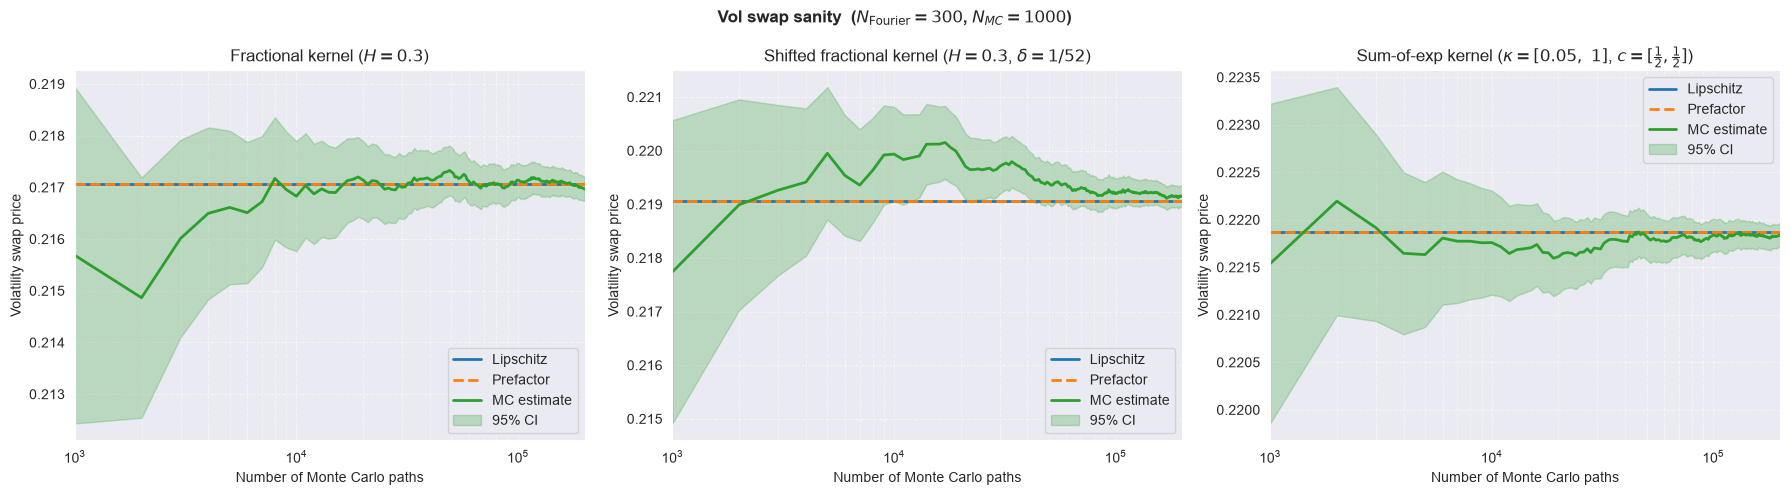

Variance-swap strike sqrt(E[V_bar]) = 0.223607  (upper bound)


,Category,Parameter,Value
0,Model,d,1
1,Model,n,1
2,Model,T,0.05
3,Model,H,0.3
4,Model,delta (shifted panel),0.0192
5,Model,kappa (sum-of-exp panel),"[0.05, 1]"
6,Model,c (sum-of-exp panel),"[0.5, 0.5]"
7,Model,Y0,[1]
8,Model,C,[[0.5]]
9,Model,rho,[[1.0]]


In [ ]:
# ---- Volatility swap (H = 0.3): Fourier vs Monte-Carlo, three kernels ----
d = 1
n = 1
T = 0.05
N_fourier = 300
N_MC = 10**3

Y0 = np.array([1.0])
H = 0.3
C = np.array([[0.5]])
rho = np.array([[1.0]])
R_W = np.array([[1.0]])
eta = np.array([[1.0]])
Gamma = np.array([[1.0]])
tilde_Gamma = compute_tilde_Gamma(n, d, Gamma)

MC = 2 * 10**5
batch_mc = 10**3

gl_deg = 80
gl_nodes, gl_weights = np.polynomial.laguerre.laggauss(gl_deg)

z95 = st.norm.ppf(0.975)

# E[V_bar_T] = int_0^T G_0(s)^2 ds = T (G_0 = 1); the normalisation enforces
# E[sigma^2] = G_0^2, so this holds for every kernel (fractional, shifted, sum-of-exponentials).
E_Vbar = float(T)

# ---- Consistent styling across the panels ----
COL_LIP, LS_LIP = "C0", "-"       # Lipschitz (Fourier)
COL_PF,  LS_PF = "C1", "--"       # Prefactor (Fourier)
COL_MC,  LS_MC = "C2", "-"        # Monte-Carlo estimate
COL_CI,  LS_CI = "C2", ":"        # 95% confidence interval

# Three kernels: fractional, shifted fractional, sum of two exponentials.
# Each builder maps N -> (KK, SIG_eta_free).
kernel_configs = [
    (rf"Fractional kernel ($H={H}$)",
     lambda N_: shifted_fractional_KK_SIG_d1_n1(N=N_, T=T, H=H, delta=0.0)),
    (rf"Shifted fractional kernel ($H={H}$, $\delta=1/52$)",
     lambda N_: shifted_fractional_KK_SIG_d1_n1(N=N_, T=T, H=H, delta=1.0 / 52.0)),
    (r"Sum-of-exp kernel ($\kappa=[0.05,\ 1]$, $c=[\frac{1}{2},\frac{1}{2}]$)",
     lambda N_: sum_exponential_KK_SIG_d1_n1(N=N_, T=T, kappa_array=np.array([[0.05, 1.0]]), c_array=np.array([[0.5, 0.5]]))),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (kernel_title, kernel_builder) in zip(axes, kernel_configs):
    # ---- Fourier side (N_fourier) ----
    KK_f, SIG_eta_free_f = kernel_builder(N_fourier)
    SIG_f = np.kron(SIG_eta_free_f, eta @ eta.T)
    G0_f = np.ones((N_fourier, d, d))
    MM_f = compute_M_matrix(n=n, d=d, N=N_fourier, SIG=SIG_f, Gamma=Gamma, tilde_Gamma=tilde_Gamma, rho=rho, G0=G0_f, Y0=Y0)
    V_det = compute_V_matrix_for_fourier(n, N_fourier, T, eta, R_W, KK_f, SIG_f, MM_f)
    sqrt_V_det = matrix_sqrt_psd(V_det)
    g_tilde = compute_tilde_g_N0(Y0, n, N_fourier, MM_f)

    # Laplace transform xi(s) = E[exp(-s V_bar_T)] = FLT(u = 0, w = -s) on the Gauss-Laguerre nodes:
    # Lipschitz and prefactor-free
    u_array = np.zeros((gl_deg, d), dtype=complex)
    w_array = (-gl_nodes).reshape(-1, 1, 1).astype(complex)
    disc_vals, det_vals = vss_fourier_laplace_discontinuous_det(u_array, w_array, n, d, N_fourier, T, C, rho, R_W, V_det, g_tilde)
    xi_laplace_lip = vss_fourier_laplace_det_lip_based(disc_vals, det_vals)
    xi_laplace_pf = vss_fourier_laplace_det_prefactor_free(u_array, w_array, n, d, N_fourier, T, C, rho, R_W, V_det, sqrt_V_det, g_tilde)

    vol_swap_fourier_lip = vol_swap_price_fourier(xi_laplace_lip, E_Vbar, gl_nodes, gl_weights)
    vol_swap_fourier_pf = vol_swap_price_fourier(xi_laplace_pf, E_Vbar, gl_nodes, gl_weights)

    # ---- Monte-Carlo side (N_MC) ----
    KK_m, SIG_eta_free_m = kernel_builder(N_MC)
    SIG_m = np.kron(SIG_eta_free_m, eta @ eta.T)
    G0_m = np.ones((N_MC, d, d))
    MM_m = compute_M_matrix(n=n, d=d, N=N_MC, SIG=SIG_m, Gamma=Gamma, tilde_Gamma=tilde_Gamma, rho=rho, G0=G0_m, Y0=Y0)
    V_mc = compute_V_matrix_for_mc(d, N_MC, T, eta, C, rho, KK_m, SIG_m, MM_m)
    chol_V_mc = spectral_cholesky(V_mc, tol=1e-12)

    MC_path, vs_path, vs_std = mc_vol_swap_price(
        d=d, N=N_MC, T=T, Y0=Y0, rho=rho, MM=MM_m, chol_V=chol_V_mc,
        MC=MC, batch_mc=batch_mc, seed=None, use_antithetic=False,
    )

    # ---- Tube on the volatility swap price ----
    ax.axhline(vol_swap_fourier_lip, color=COL_LIP, ls=LS_LIP, linewidth=2, label="Lipschitz")
    ax.axhline(vol_swap_fourier_pf, color=COL_PF, ls=LS_PF, linewidth=2, label="Prefactor")
    ax.plot(MC_path, vs_path, color=COL_MC, ls=LS_MC, linewidth=2, label="MC estimate")
    ax.fill_between(MC_path, vs_path - z95 * vs_std, vs_path + z95 * vs_std,
                    color=COL_CI, alpha=0.25, label="95% CI")
    ax.set_xscale("log")
    ax.set_xlim(MC_path[0], MC_path[-1])
    ax.set_xlabel("Number of Monte Carlo paths")
    ax.set_ylabel("Volatility swap price")
    ax.set_title(kernel_title)
    ax.grid(True, which="both", ls="--", alpha=0.5)
    ax.legend()

    print(f"[{kernel_title}]")
    print(f"  Fourier (Lipschitz) vol swap = {vol_swap_fourier_lip:.6f}")
    print(f"  Fourier (prefactor) vol swap = {vol_swap_fourier_pf:.6f}")
    print(f"  MC vol swap                  = {vs_path[-1]:.6f} +/- {z95*vs_std[-1]:.6f} (95% CI)")

fig.suptitle(rf"Vol swap sanity  ($N_{{\mathrm{{Fourier}}}}={N_fourier}$, $N_{{MC}}={N_MC}$)",
             fontweight="bold")
plt.tight_layout()
plt.tight_layout()
fig.savefig(
    PLOTS_DIRECTORY / 'vol_swap_fourier_vs_mc.png',
    dpi=200,
    bbox_inches='tight',
)
plt.show()

print(f"Variance-swap strike sqrt(E[V_bar]) = {np.sqrt(E_Vbar):.6f}  (upper bound)")

# ---- Parameters used in this sanity check ----
params_df = format_params_df([
    ("Model", "d", d),
    ("Model", "n", n),
    ("Model", "T", T),
    ("Model", "H", H),
    ("Model", "delta (shifted panel)", 1.0 / 52.0),
    ("Model", "kappa (sum-of-exp panel)", [0.05, 1.0]),
    ("Model", "c (sum-of-exp panel)", [0.5, 0.5]),
    ("Model", "Y0", Y0.tolist()),
    ("Model", "C", C.tolist()),
    ("Model", "rho", rho.tolist()),
    ("Model", "R_W", R_W.tolist()),
    ("Model", "eta", eta.tolist()),
    ("Model", "Gamma", Gamma.tolist()),
    ("Fourier", "N_fourier", N_fourier),
    ("Fourier", "gl_deg", gl_deg),
    ("Monte-Carlo", "N_MC", N_MC),
    ("Monte-Carlo", "MC", MC),
    ("Monte-Carlo", "batch_mc", batch_mc),
])
display(params_df)

## Fourier vs Fourier

The framework of "Complex Discontinuities of the Square Root of Fredholm Determinants in the Volterra Stein–Stein Stochastic Volatility Model" https://epubs.siam.org/doi/abs/10.1137/25M1741601 studies an additive version of our framework ($G_0$ is added to the volatility factor, whereas in our framework, it is multiplied). The formula for the Fourier transform is slightly different from in both framework, so we use the implementation from "Complex Discontinuities of the Square Root of Fredholm Determinants in the Volterra Stein–Stein Stochastic Volatility Model", available at https://colab.research.google.com/drive/1O87IJpqGo1E8oGXnZxFqamYnm3Oa-_8d?usp=sharing as an alternative benchmark. This is done in the case of the fractional kernel.

Here $G_0(t)=\sqrt{\mathbb{E}[Y_t^2]}$ and $\Gamma=[1]$, so the normalisation gives $\sigma(t,Y_t)=Y_t$.


In [ ]:
d = 1
n = 1
T = 1.
S_0 = 1.0
K_atm = 1.0
Y0 = np.array([1.0])
H = 0.3
C = np.array([[-0.8]])            
rho = np.array([[1.0]])
R_W = np.array([[1.0]])
eta = np.array([[0.3]])
Gamma = np.array([[1.0]])
tilde_Gamma = compute_tilde_Gamma(n, d, Gamma)

gl_deg = 80
gl_nodes, gl_weights = np.polynomial.laguerre.laggauss(gl_deg)
u_array = (0.5 + 1j * gl_nodes).reshape(-1, 1)
w_array = np.zeros((gl_deg, d, d), dtype=complex)

call_price_benchmark = 0.36450214

N_fourier_disc = np.array([10,100,200,300,400,500,600,700,800,900,950,1000])
call_prices = np.zeros(len(N_fourier_disc))
for i, N_fourier in enumerate(N_fourier_disc):
    KK_f, SIG_eta_free_f = shifted_fractional_KK_SIG_d1_n1(N_fourier, T, H=H, delta=0.0)
    SIG_f = np.kron(SIG_eta_free_f, eta @ eta.T)
    G0_f = np.reshape(np.sqrt(Y0@Y0.T + np.diag(SIG_f)), (N_fourier,d,d))
    MM_f = compute_M_matrix(n=n, d=d, N=N_fourier, SIG=SIG_f, Gamma=Gamma, tilde_Gamma=tilde_Gamma, rho=rho, G0=G0_f, Y0=Y0)
    V_det = compute_V_matrix_for_fourier(n, N_fourier, T, eta, R_W, KK_f, SIG_f, MM_f)
    sqrt_V_det = matrix_sqrt_psd(V_det)
    g_tilde = compute_tilde_g_N0(Y0, n, N_fourier, MM_f)
    flt_vals_pf = vss_fourier_laplace_det_prefactor_free(u_array, w_array, n, d, N_fourier, T, C, rho, R_W, V_det, sqrt_V_det, g_tilde)
    call_fourier_pf = call_put_price_fourier(flt_vals_pf, S_0, np.array([K_atm]), gl_nodes, gl_weights, option_type="call")

    call_prices[i] = call_fourier_pf[0]

/Users/maximeguellil/.venvs/volterra-stein-stein/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


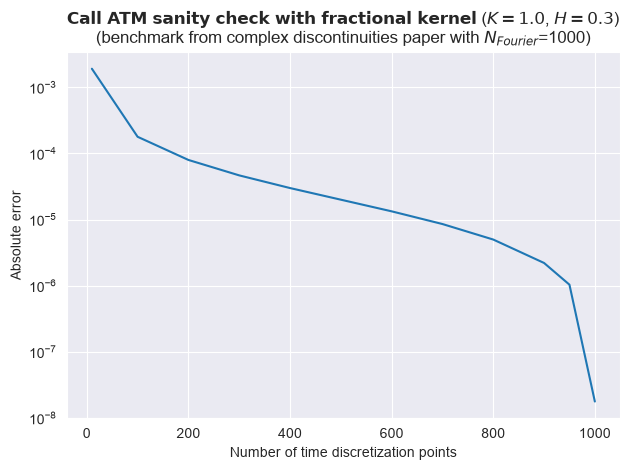

In [ ]:
plt.plot(N_fourier_disc, np.abs(call_prices - call_price_benchmark))
plt.yscale('log')
plt.title(
    rf"$\bf{{Call\ ATM\ sanity\ check\ with\ fractional\ kernel}}$ "
    rf"($K={K_atm}$, $H={H}$)"
    "\n"
    "(benchmark from complex discontinuities paper with $N_{Fourier}$=1000)"
)
plt.xlabel("Number of time discretization points")
plt.ylabel("Absolute error")
plt.tight_layout()
plt.savefig(
    PLOTS_DIRECTORY / 'call_fourier_vs_fourier.png',
    dpi=200,
    bbox_inches='tight',
)
plt.show()